# Comprensión de datos y EDA

Análisis exploratorio de la base de créditos históricos. El objetivo es entender los datos antes de modelar: qué hay, qué falta, qué está raro y qué variables parecen importar para predecir si un cliente paga a tiempo (`Pago_atiempo`).

Secciones:
1. Exploración inicial: caracterización de variables, nulos, tipos de datos y variables candidatas a irrelevantes
2. Análisis univariable
3. Análisis bivariable
4. Análisis multivariable
5. Conclusiones: reglas de validación, transformaciones y atributos derivados

# 1. Exploración inicial

## 1.1 Librerías y configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1.2 Carga de datos

Se lee el CSV generado en `Cargar_datos.ipynb`. Se guarda una copia intacta (`df_original`) y se trabaja sobre `df`, para poder comparar antes y después de los ajustes.

In [2]:
RUTA_CSV = Path("../Base_de_datos.csv")

df_original = pd.read_csv(RUTA_CSV, parse_dates=["fecha_prestamo"])
df = df_original.copy()
print("Filas y columnas:", df.shape)

Filas y columnas: (10763, 23)


### Variable objetivo

El enunciado no nombra la variable objetivo. El profesor confirmó que es `Pago_atiempo`. La dirección (1 = pagó a tiempo, 0 = no) viene de su diccionario, que la da como "probable". Estas son las razones por las que encaja:

- El enunciado pide anticipar el comportamiento de nuevos usuarios y evaluar con métricas de clasificación (precisión, recall, F1, ROC-AUC). Por eso el objetivo debe ser una variable binaria.
- Entre las columnas con solo dos valores, `Pago_atiempo` es la única que describe un **resultado** del crédito.
- Su nombre encaja con un modelo de riesgo crediticio y es la última columna de la base.

In [3]:
columnas_dos_valores = [col for col in df.columns if df[col].nunique() == 2]
print("Columnas con exactamente dos valores distintos:", columnas_dos_valores)

Columnas con exactamente dos valores distintos: ['tipo_laboral', 'Pago_atiempo']


`tipo_laboral` también tiene dos valores (Empleado e Independiente), pero describe al cliente al pedir el crédito, no un resultado posterior. No sirve como objetivo.

## 1.3 Descripción general

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

In [5]:
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,7,2024-12-21 11:31:35,"3,692,160.00",10,42,Independiente,8000000,2500000,341296,88.77,695.00,10,5,0.00,"51,258.00","51,258.00",0.00,5,0,0,"908,526.00",Estable,1
1,4,2025-04-22 09:47:35,"840,000.00",6,60,Empleado,3000000,2000000,124876,95.23,789.00,3,1,0.00,"8,673.00","8,673.00",0.00,0,0,2,"939,017.00",Creciente,1
2,9,2026-01-08 12:22:40,"5,974,028.40",10,36,Independiente,4036000,829000,529554,47.61,740.00,4,5,0.00,"18,702.00","18,702.00",0.00,3,0,0,NaN,NaN,0
3,4,2025-08-04 12:04:10,"1,671,240.00",6,48,Empleado,1524547,498000,252420,95.23,837.00,4,4,0.00,"15,782.00","15,782.00",0.00,3,0,0,"1,536,193.00",Creciente,1
4,9,2025-04-26 11:24:26,"2,781,636.00",11,44,Empleado,5000000,4000000,217037,95.23,771.00,4,6,0.00,"204,804.00","204,804.00",0.00,3,0,1,"933,473.00",Creciente,1


## 1.4 Caracterización de las variables

Cada variable se clasifica según lo que representa, no según cómo la guardó pandas:

- **Numérica continua:** puede tomar cualquier valor en un rango (montos, puntajes).
- **Numérica discreta:** solo toma valores enteros (conteos, meses, años).
- **Categórica nominal:** categorías sin orden. Es **dicotómica** si tiene 2 categorías y **politómica** si tiene más de 2.
- **Categórica ordinal:** categorías con un orden natural.

El orden de `tendencia_ingresos` (Decreciente < Estable < Creciente) es una suposición razonable, no un dato del enunciado.

In [6]:
caracterizacion = pd.DataFrame(
    [
        ("tipo_credito", "Categórica nominal (politómica)", "Código numérico; no es una cantidad"),
        ("fecha_prestamo", "Fecha", "Fecha y hora del préstamo"),
        ("capital_prestado", "Numérica continua", "Monto prestado"),
        ("plazo_meses", "Numérica discreta", "Plazo en meses"),
        ("edad_cliente", "Numérica discreta", "Edad en años"),
        ("tipo_laboral", "Categórica nominal (dicotómica)", "Empleado o Independiente"),
        ("salario_cliente", "Numérica continua", "Salario declarado"),
        ("total_otros_prestamos", "Numérica continua", "Monto de otros préstamos"),
        ("cuota_pactada", "Numérica continua", "Cuota del crédito"),
        ("puntaje", "Numérica continua", "Escala desconocida (ver 1.7)"),
        ("puntaje_datacredito", "Numérica continua", "Escala desconocida (ver 1.7)"),
        ("cant_creditosvigentes", "Numérica discreta", "Conteo"),
        ("huella_consulta", "Numérica discreta", "Conteo"),
        ("saldo_mora", "Numérica continua", "Saldo vencido"),
        ("saldo_total", "Numérica continua", "Saldo total"),
        ("saldo_principal", "Numérica continua", "Saldo del capital"),
        ("saldo_mora_codeudor", "Numérica continua", "Saldo vencido del codeudor"),
        ("creditos_sectorFinanciero", "Numérica discreta", "Conteo"),
        ("creditos_sectorCooperativo", "Numérica discreta", "Conteo"),
        ("creditos_sectorReal", "Numérica discreta", "Conteo"),
        ("promedio_ingresos_datacredito", "Numérica continua", "Ingreso promedio reportado"),
        ("tendencia_ingresos", "Categórica ordinal (politómica)", "Decreciente < Estable < Creciente"),
        ("Pago_atiempo", "Categórica nominal (dicotómica)", "Variable objetivo: 1 = pagó a tiempo, 0 = no"),
    ],
    columns=["variable", "clase", "nota"],
).set_index("variable")

assert set(caracterizacion.index) == set(df.columns), "Hay columnas sin clasificar"
caracterizacion.loc[df.columns]

,clase,nota
variable,,
tipo_credito,Categórica nominal (politómica),Código numérico; no es una cantidad
fecha_prestamo,Fecha,Fecha y hora del préstamo
capital_prestado,Numérica continua,Monto prestado
plazo_meses,Numérica discreta,Plazo en meses
edad_cliente,Numérica discreta,Edad en años
tipo_laboral,Categórica nominal (dicotómica),Empleado o Independiente
salario_cliente,Numérica continua,Salario declarado
total_otros_prestamos,Numérica continua,Monto de otros préstamos
cuota_pactada,Numérica continua,Cuota del crédito


In [7]:
columnas_numericas = [
    "capital_prestado", "plazo_meses", "edad_cliente", "salario_cliente",
    "total_otros_prestamos", "cuota_pactada", "puntaje", "puntaje_datacredito",
    "cant_creditosvigentes", "huella_consulta", "saldo_mora", "saldo_total",
    "saldo_principal", "saldo_mora_codeudor", "creditos_sectorFinanciero",
    "creditos_sectorCooperativo", "creditos_sectorReal",
    "promedio_ingresos_datacredito",
]
columnas_categoricas = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]
objetivo = "Pago_atiempo"

## 1.5 Valores nulos

Cuántos faltan en cada columna y qué porcentaje del total representan.

In [8]:
nulos = df.isna().sum()
resumen_nulos = pd.DataFrame({"nulos": nulos, "porcentaje": nulos / len(df) * 100})
resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,porcentaje
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


Dos columnas de ingresos tienen casi la misma cantidad de nulos. Comprobamos si faltan en las mismas filas.

In [9]:
faltan_juntas = (df["promedio_ingresos_datacredito"].isna() == df["tendencia_ingresos"].isna()).mean()
print(f"Filas donde ambas faltan o ambas existen: {faltan_juntas:.2%}")

Filas donde ambas faltan o ambas existen: 99.98%


### Unificar la representación de los nulos

Un nulo puede venir como `NaN` o como texto (`""`, `NA`, `N/A`, `null`, `?`, etc.). Si hay varias formas en la misma base, pandas solo reconoce `NaN`. Buscamos marcadores de texto en las columnas no numéricas y, si existen, los convertimos a `NaN`.

In [10]:
marcadores = ["", "na", "n/a", "nan", "null", "none", "?", "-", "s/d", "sin dato"]
columnas_texto = df.select_dtypes(exclude=["number", "datetime"]).columns

encontrados = {}
for col in columnas_texto:
    limpio = df[col].astype("string").str.strip().str.lower()
    mascara = limpio.isin(marcadores).fillna(False).to_numpy(dtype=bool)
    encontrados[col] = int(mascara.sum())
    df.loc[mascara, col] = np.nan

pd.Series(encontrados, name="marcadores de nulo encontrados").to_frame()

,marcadores de nulo encontrados
tipo_laboral,0
tendencia_ingresos,0


Ninguna columna de texto trae nulos disfrazados: todos los nulos ya están como `NaN`.

Distinto es el caso de los **códigos numéricos** que podrían significar "sin dato" (una edad de 122 años, un puntaje de 0, -7 o 999). No los convertimos a nulo todavía, porque no sabemos qué significan. El diccionario del profesor no los aclara, así que se tratan como supuestos (5.2 y 5.4).

In [11]:
codigos = pd.Series(
    {
        "edad_cliente entre 121 y 123": df["edad_cliente"].between(121, 123).sum(),
        "puntaje_datacredito == 0": (df["puntaje_datacredito"] == 0).sum(),
        "puntaje_datacredito < 0": (df["puntaje_datacredito"] < 0).sum(),
        "puntaje_datacredito == 999": (df["puntaje_datacredito"] == 999).sum(),
        "salario_cliente == 0": (df["salario_cliente"] == 0).sum(),
    },
    name="filas",
)
codigos.to_frame()

,filas
edad_cliente entre 121 y 123,150
puntaje_datacredito == 0,145
puntaje_datacredito < 0,1
puntaje_datacredito == 999,1
salario_cliente == 0,24


**Lectura.** Hay nulos en 7 de las 23 columnas. Los más grandes son `tendencia_ingresos` y `promedio_ingresos_datacredito` (27.2% cada una), y faltan casi siempre en las mismas filas (99.98%). Probablemente tienen un mismo origen, por ejemplo clientes sin historial de ingresos en Datacrédito, pero es una hipótesis por confirmar. `saldo_mora_codeudor` tiene 5.5% de nulos, que podrían significar que no hay codeudor.

## 1.6 Duplicados

In [12]:
print("Filas duplicadas exactas:", df.duplicated().sum())

Filas duplicadas exactas: 0


## 1.7 Valores sospechosos

Valores que no tienen sentido de negocio. Aquí solo se **cuentan y se documentan**. Qué hacer con ellos se decide en 1.9 y en el Avance 2.

In [13]:
sospechosos = {
    "edad_cliente > 100": (df["edad_cliente"] > 100).sum(),
    "salario_cliente == 0": (df["salario_cliente"] == 0).sum(),
    "salario_cliente > 100 millones": (df["salario_cliente"] > 100_000_000).sum(),
    "total_otros_prestamos > 100 millones": (df["total_otros_prestamos"] > 100_000_000).sum(),
    "puntaje < 0": (df["puntaje"] < 0).sum(),
    "puntaje_datacredito < 0": (df["puntaje_datacredito"] < 0).sum(),
    "plazo_meses > 60": (df["plazo_meses"] > 60).sum(),
}
pd.Series(sospechosos, name="filas").to_frame()

,filas
edad_cliente > 100,150
salario_cliente == 0,24
salario_cliente > 100 millones,74
total_otros_prestamos > 100 millones,44
puntaje < 0,135
puntaje_datacredito < 0,1
plazo_meses > 60,1


`tendencia_ingresos` debería tener tres categorías: `Creciente`, `Estable` y `Decreciente`. Revisamos si hay algo más.

In [14]:
validas = ["Creciente", "Estable", "Decreciente"]
no_validas = df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(validas)

print("Filas con un valor que no es una categoría válida:", no_validas.sum())
df.loc[no_validas, "tendencia_ingresos"].head(10).to_frame()

Filas con un valor que no es una categoría válida: 58


,tendencia_ingresos
157,8315
168,0
440,158042
486,3978
705,9147
1185,8315
1188,168750
1898,-28589
2027,8315
2038,1000000


`puntaje` tiene la mediana, el percentil 75 y el máximo en el mismo valor. Miramos cuántas filas lo repiten y qué proporción pagó a tiempo en cada grupo.

In [15]:
valor_repetido = df["puntaje"].max()
print("Valor máximo de puntaje:", round(valor_repetido, 6))
print(f"Filas con exactamente ese valor: {(df['puntaje'] == valor_repetido).mean():.1%}")

grupo_puntaje = pd.Series(
    np.select(
        [df["puntaje"] < 0, df["puntaje"] == valor_repetido],
        ["Negativo", "Valor repetido"],
        default="Resto",
    ),
    index=df.index,
    name="grupo_puntaje",
)
df.groupby(grupo_puntaje)["Pago_atiempo"].agg(filas="size", proporcion_pago_a_tiempo="mean")

Valor máximo de puntaje: 95.227787
Filas con exactamente ese valor: 87.4%


,filas,proporcion_pago_a_tiempo
grupo_puntaje,,
Negativo,135,0.00
Resto,1221,0.69
Valor repetido,9407,1.00


**Lectura.**
- **Edad:** 150 filas tienen entre 121 y 123 años y ninguna cae entre 80 y 120. Parece un código de "edad desconocida", no una edad.
- **Salario y otros préstamos:** hay valores de miles de millones (el máximo del salario es 22,000 millones, con una mediana de 3 millones). Son casi seguro errores de digitación o de unidades.
- **`puntaje`:** el 87.4% de las filas tiene el mismo valor, y todas pagaron a tiempo. Las 135 filas con puntaje negativo no pagaron a tiempo. Eso es una **señal de alerta de fuga de información** (*data leakage*): la variable podría calcularse con el resultado que queremos predecir. Es una hipótesis. La decisión de excluirla del modelo se toma en 3.2.
- **`tendencia_ingresos`:** 58 filas traen números en lugar de una categoría.

## 1.8 Variables candidatas a irrelevantes

Una variable aporta poco cuando casi todas las filas tienen el mismo valor, porque no permite distinguir a un cliente de otro. Calculamos, para cada columna, el porcentaje de filas (entre las no nulas) que repite su valor más frecuente.

In [16]:
mas_frecuente = df.apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)

resumen_constantes = pd.DataFrame(
    {
        "pct_valor_mas_frecuente": mas_frecuente,
        "valores_distintos": df.nunique(),
        "nulos": df.isna().sum(),
    }
)
resumen_constantes.sort_values("pct_valor_mas_frecuente", ascending=False).head(8)

,pct_valor_mas_frecuente,valores_distintos,nulos
saldo_mora_codeudor,99.97,4,590
saldo_mora,99.48,55,156
Pago_atiempo,95.25,2,0
puntaje,87.40,248,0
creditos_sectorCooperativo,82.39,11,0
tipo_credito,71.98,6,0
tendencia_ingresos,67.60,46,2932
tipo_laboral,62.75,2,0


Estas son las **candidatas**. **No se eliminan todavía.** La decisión final se toma después de ver su relación con la variable objetivo (sección 3) teniendo en cuenta que el diccionario del profesor es solo una interpretación y no aclara varias variables.

In [17]:
candidatas_irrelevantes = pd.DataFrame(
    {
        "saldo_mora_codeudor": "100% en 0 salvo 3 filas; además tiene 590 nulos",
        "saldo_mora": "99.5% de las filas en 0",
        "puntaje": "87.4% en un solo valor y posible fuga de información (no es solo irrelevante: es riesgosa)",
    },
    index=["motivo"],
).T
candidatas_irrelevantes

,motivo
saldo_mora_codeudor,100% en 0 salvo 3 filas; además tiene 590 nulos
saldo_mora,99.5% de las filas en 0
puntaje,87.4% en un solo valor y posible fuga de infor...


## 1.9 Conversión de tipos y corrección de datos

Cada columna debe quedar con un tipo uniforme que corresponda a lo que representa (sección 1.4):

- `tipo_credito` y `tipo_laboral` pasan a categóricas. `tipo_credito` es un código, no una cantidad.
- `tendencia_ingresos` pasa a categórica **ordinal**. Antes, los 58 valores numéricos que no son categorías se convierten en nulo, porque no pertenecen a la variable. Es una decisión revisable (0.5% de las filas).
- `fecha_prestamo` ya es fecha.
- `Pago_atiempo` queda como 0/1.
- Los códigos numéricos raros (edad 122, puntajes 0, -7 y 999) **no se tocan aquí**: el profesor no aclaró su significado, y se tratan como supuestos en 5.2 y 5.4.

In [18]:
orden_tendencia = ["Decreciente", "Estable", "Creciente"]

df["tipo_credito"] = df["tipo_credito"].astype("category")
df["tipo_laboral"] = df["tipo_laboral"].astype("category")

invalidos = df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(orden_tendencia)
df.loc[invalidos, "tendencia_ingresos"] = np.nan
df["tendencia_ingresos"] = pd.Categorical(
    df["tendencia_ingresos"], categories=orden_tendencia, ordered=True
)

print("Valores de tendencia_ingresos convertidos a nulo:", int(invalidos.sum()))

Valores de tendencia_ingresos convertidos a nulo: 58


In [19]:
pd.DataFrame({"antes": df_original.dtypes.astype(str), "despues": df.dtypes.astype(str)})

,antes,despues
tipo_credito,int64,category
fecha_prestamo,datetime64[us],datetime64[us]
capital_prestado,float64,float64
plazo_meses,int64,int64
edad_cliente,int64,int64
tipo_laboral,str,category
salario_cliente,int64,int64
total_otros_prestamos,int64,int64
cuota_pactada,int64,int64
puntaje,float64,float64


In [20]:
df["tendencia_ingresos"].value_counts(dropna=False).to_frame("filas")

,filas
tendencia_ingresos,
Creciente,5294
NaN,2990
Decreciente,1291
Estable,1188


# 2. Análisis univariable

Se mira cada variable por separado, ya con los tipos corregidos: su distribución, sus extremos y su forma. Las relaciones con la variable objetivo vienen en la sección 3.

## 2.1 `describe()` con los tipos ajustados

In [21]:
df[columnas_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00
edad_cliente,"10,763.00",43.95,15.06,19.00,33.00,42.00,53.00,123.00
salario_cliente,"10,763.00","17,216,431.46","355,476,717.60",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,757.00",780.79,104.88,-7.00,757.00,791.00,825.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00


In [22]:
df[columnas_categoricas].describe().T

,count,unique,top,freq
tipo_credito,10763,6,4,7747
tipo_laboral,10763,2,Empleado,6754
tendencia_ingresos,7773,3,Creciente,5294


## 2.2 Variable objetivo

`Pago_atiempo`: 1 = pagó a tiempo, 0 = no pagó a tiempo.

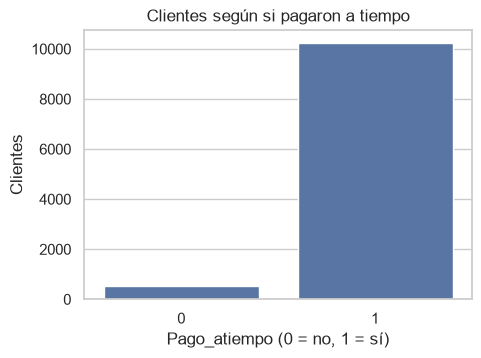

,clientes,porcentaje
Pago_atiempo,,
1,10252,95.25
0,511,4.75


In [23]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Pago_atiempo", ax=ax)
ax.set_title("Clientes según si pagaron a tiempo")
ax.set_xlabel("Pago_atiempo (0 = no, 1 = sí)")
ax.set_ylabel("Clientes")
plt.show()

conteo = df["Pago_atiempo"].value_counts().to_frame("clientes")
conteo["porcentaje"] = conteo["clientes"] / len(df) * 100
conteo

**Lectura.** Solo el 4.7% de los clientes no pagó a tiempo. La base está muy desbalanceada: un modelo que dijera siempre "pagará a tiempo" acertaría el 95.3% de las veces sin aprender nada. Por eso, en el Avance 2, la exactitud (*accuracy*) no sirve como métrica y hay que mirar recall, F1 y ROC-AUC.

## 2.3 Variables numéricas

### Estadísticos descriptivos

- **Tendencia central:** media, mediana y moda.
- **Posición:** mínimo, máximo, cuartiles (Q1 y Q3).
- **Dispersión:** rango, rango intercuartílico (IQR = Q3 - Q1), varianza y desviación estándar.
- **Forma:** *skewness* (asimetría; 0 es simétrica y positivo indica cola a la derecha) y *kurtosis* (qué tan pesadas son las colas; valores altos indican extremos).

In [24]:
num = df[columnas_numericas]
q1 = num.quantile(0.25)
q3 = num.quantile(0.75)

estadisticos = pd.DataFrame(
    {
        "media": num.mean(),
        "mediana": num.median(),
        "moda": num.mode().iloc[0],
        "min": num.min(),
        "max": num.max(),
        "rango": num.max() - num.min(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "varianza": num.var(),
        "desv_std": num.std(),
        "skewness": num.skew(),
        "kurtosis": num.kurt(),
    }
)
estadisticos

,media,mediana,moda,min,max,rango,Q1,Q3,IQR,varianza,desv_std,skewness,kurtosis
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80","1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",3.72,35.32
plazo_meses,10.58,10.00,6.00,2.00,90.00,88.00,6.00,12.00,6.00,43.98,6.63,2.46,7.78
edad_cliente,43.95,42.00,40.00,19.00,123.00,104.00,33.00,53.00,20.00,226.83,15.06,1.93,7.87
salario_cliente,"17,216,431.46","3,000,000.00","3,000,000.00",0.00,"22,000,000,000.00","22,000,000,000.00","2,000,000.00","4,875,808.00","2,875,808.00","126,363,696,758,146,032.00","355,476,717.60",43.78,"2,211.23"
total_otros_prestamos,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"6,787,675,263.00","6,787,675,263.00","500,000.00","2,000,000.00","1,500,000.00","14,022,897,787,155,474.00","118,418,316.94",38.46,"1,719.28"
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00","121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",3.79,26.65
puntaje,91.17,95.23,95.23,-38.01,95.23,133.24,95.23,95.23,0.00,271.11,16.47,-4.87,24.08
puntaje_datacredito,780.79,791.00,0.00,-7.00,999.00,"1,006.00",757.00,825.00,68.00,"10,999.40",104.88,-5.64,39.44
cant_creditosvigentes,5.73,5.00,4.00,0.00,62.00,62.00,3.00,8.00,5.00,15.82,3.98,1.80,8.62
huella_consulta,4.23,4.00,2.00,0.00,29.00,29.00,2.00,6.00,4.00,9.39,3.06,1.49,4.00


### Histogramas

Como hay valores extremos (salarios de miles de millones, por ejemplo), un histograma normal queda aplastado contra el cero. Cada gráfico muestra los valores hasta el **percentil 99**. Eso deja fuera el 1% más alto de cada variable, que se revisa por separado más abajo.

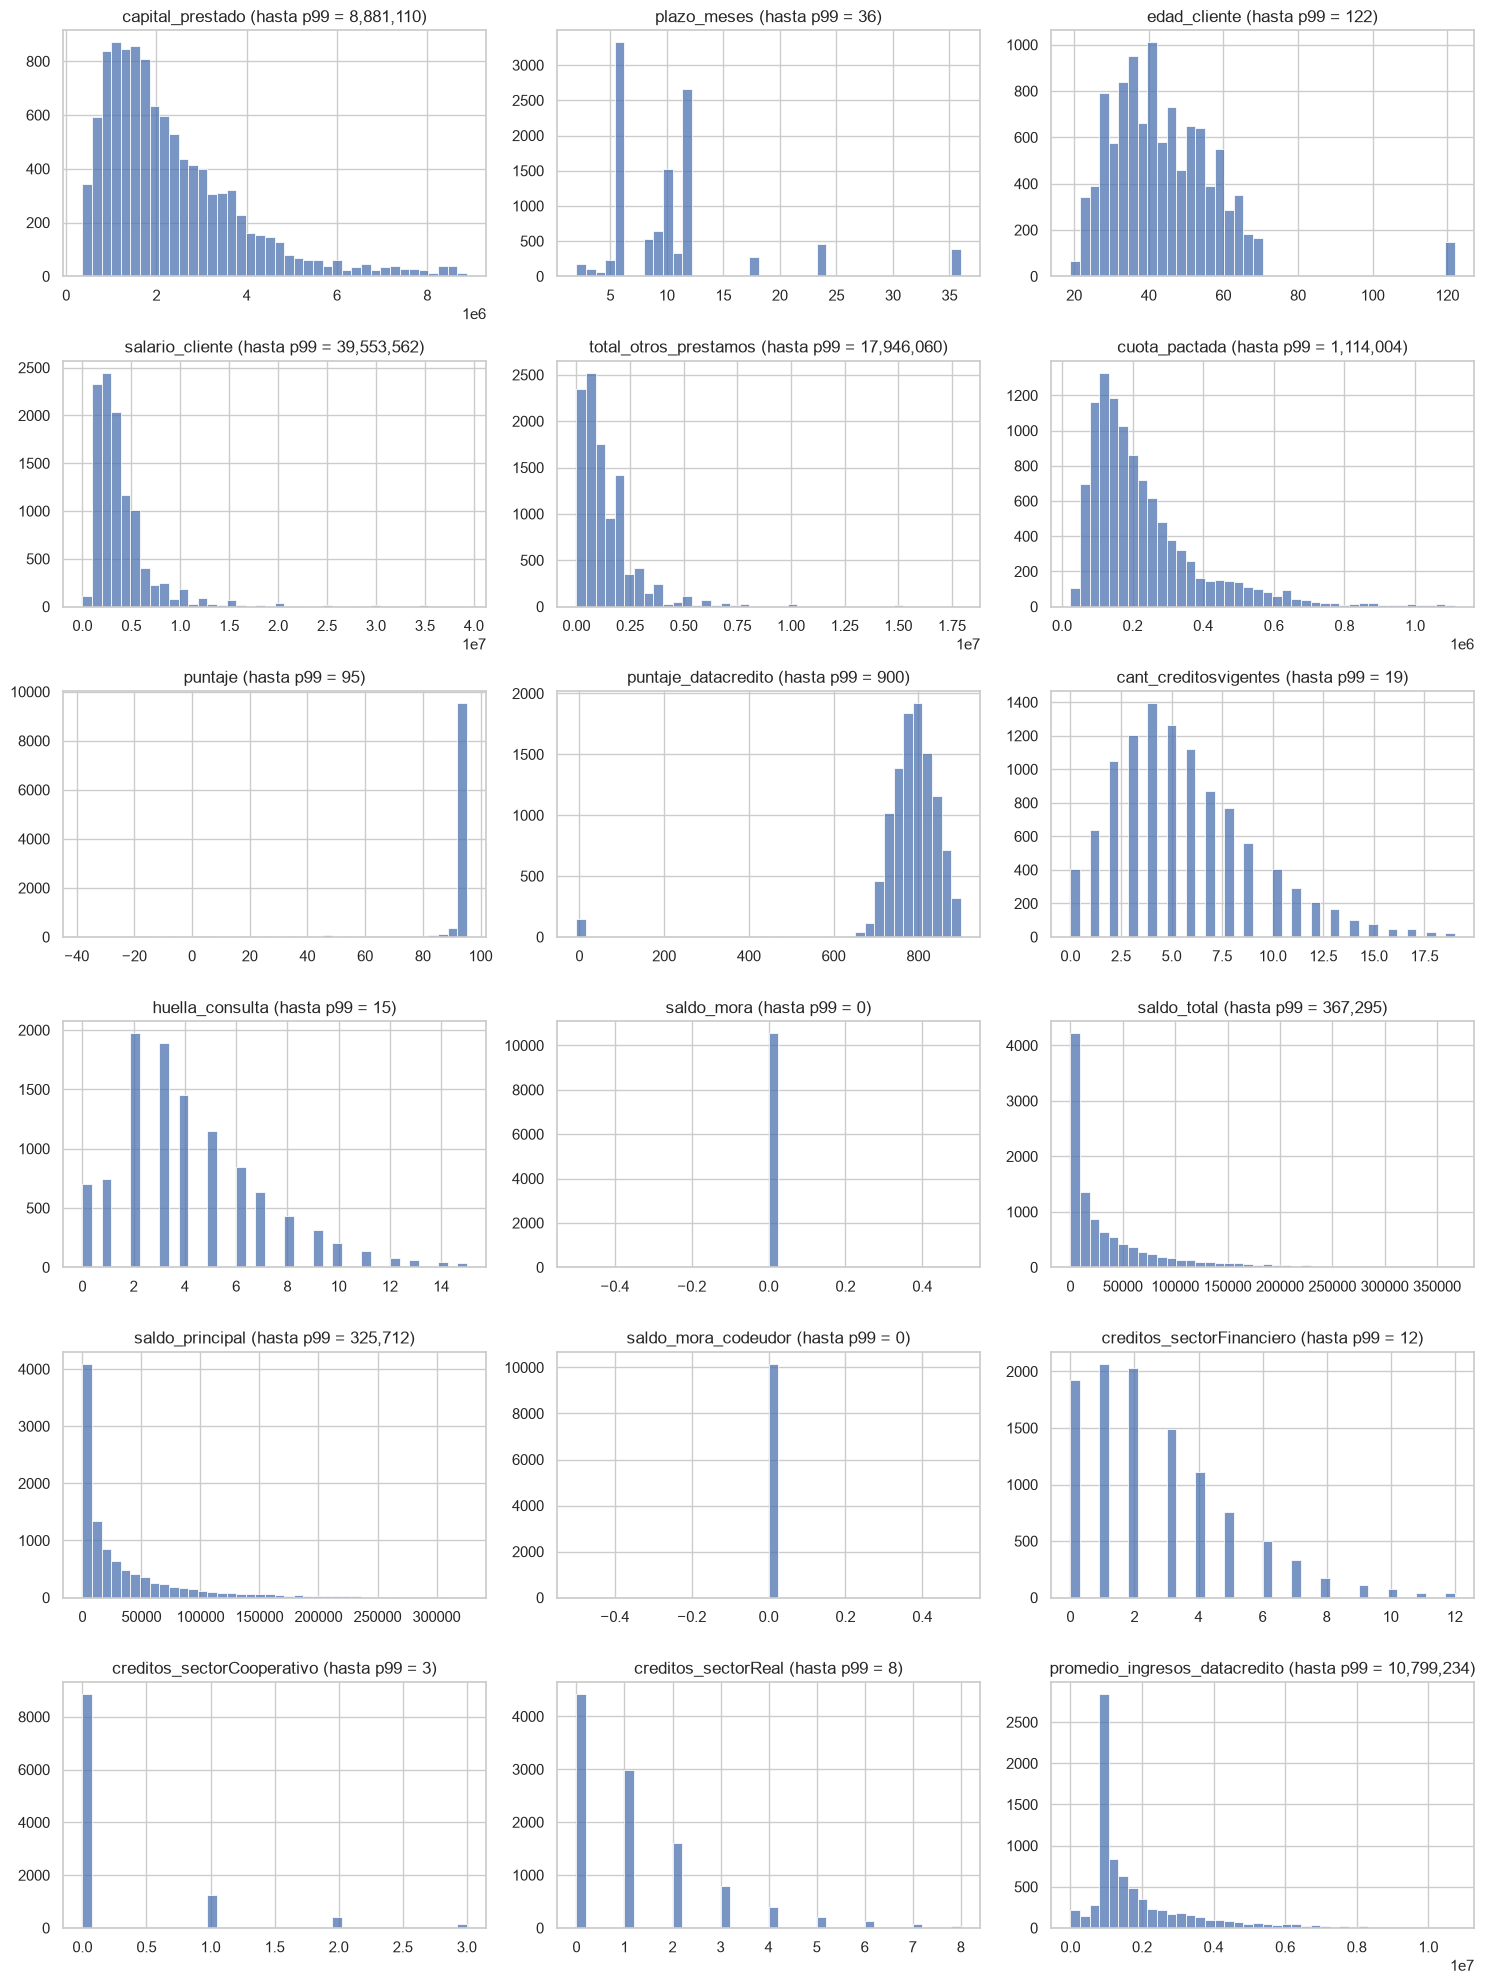

In [25]:
fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, col in zip(axes.flat, columnas_numericas):
    serie = df[col].dropna()
    limite = serie.quantile(0.99)
    sns.histplot(serie[serie <= limite], bins=40, ax=ax)
    ax.set_title(f"{col} (hasta p99 = {limite:,.0f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Boxplots

La caja va de Q1 a Q3, la línea interna es la mediana y los puntos son valores atípicos según la regla del IQR (más allá de 1.5 veces el IQR). Igual que arriba, se muestran hasta el percentil 99.

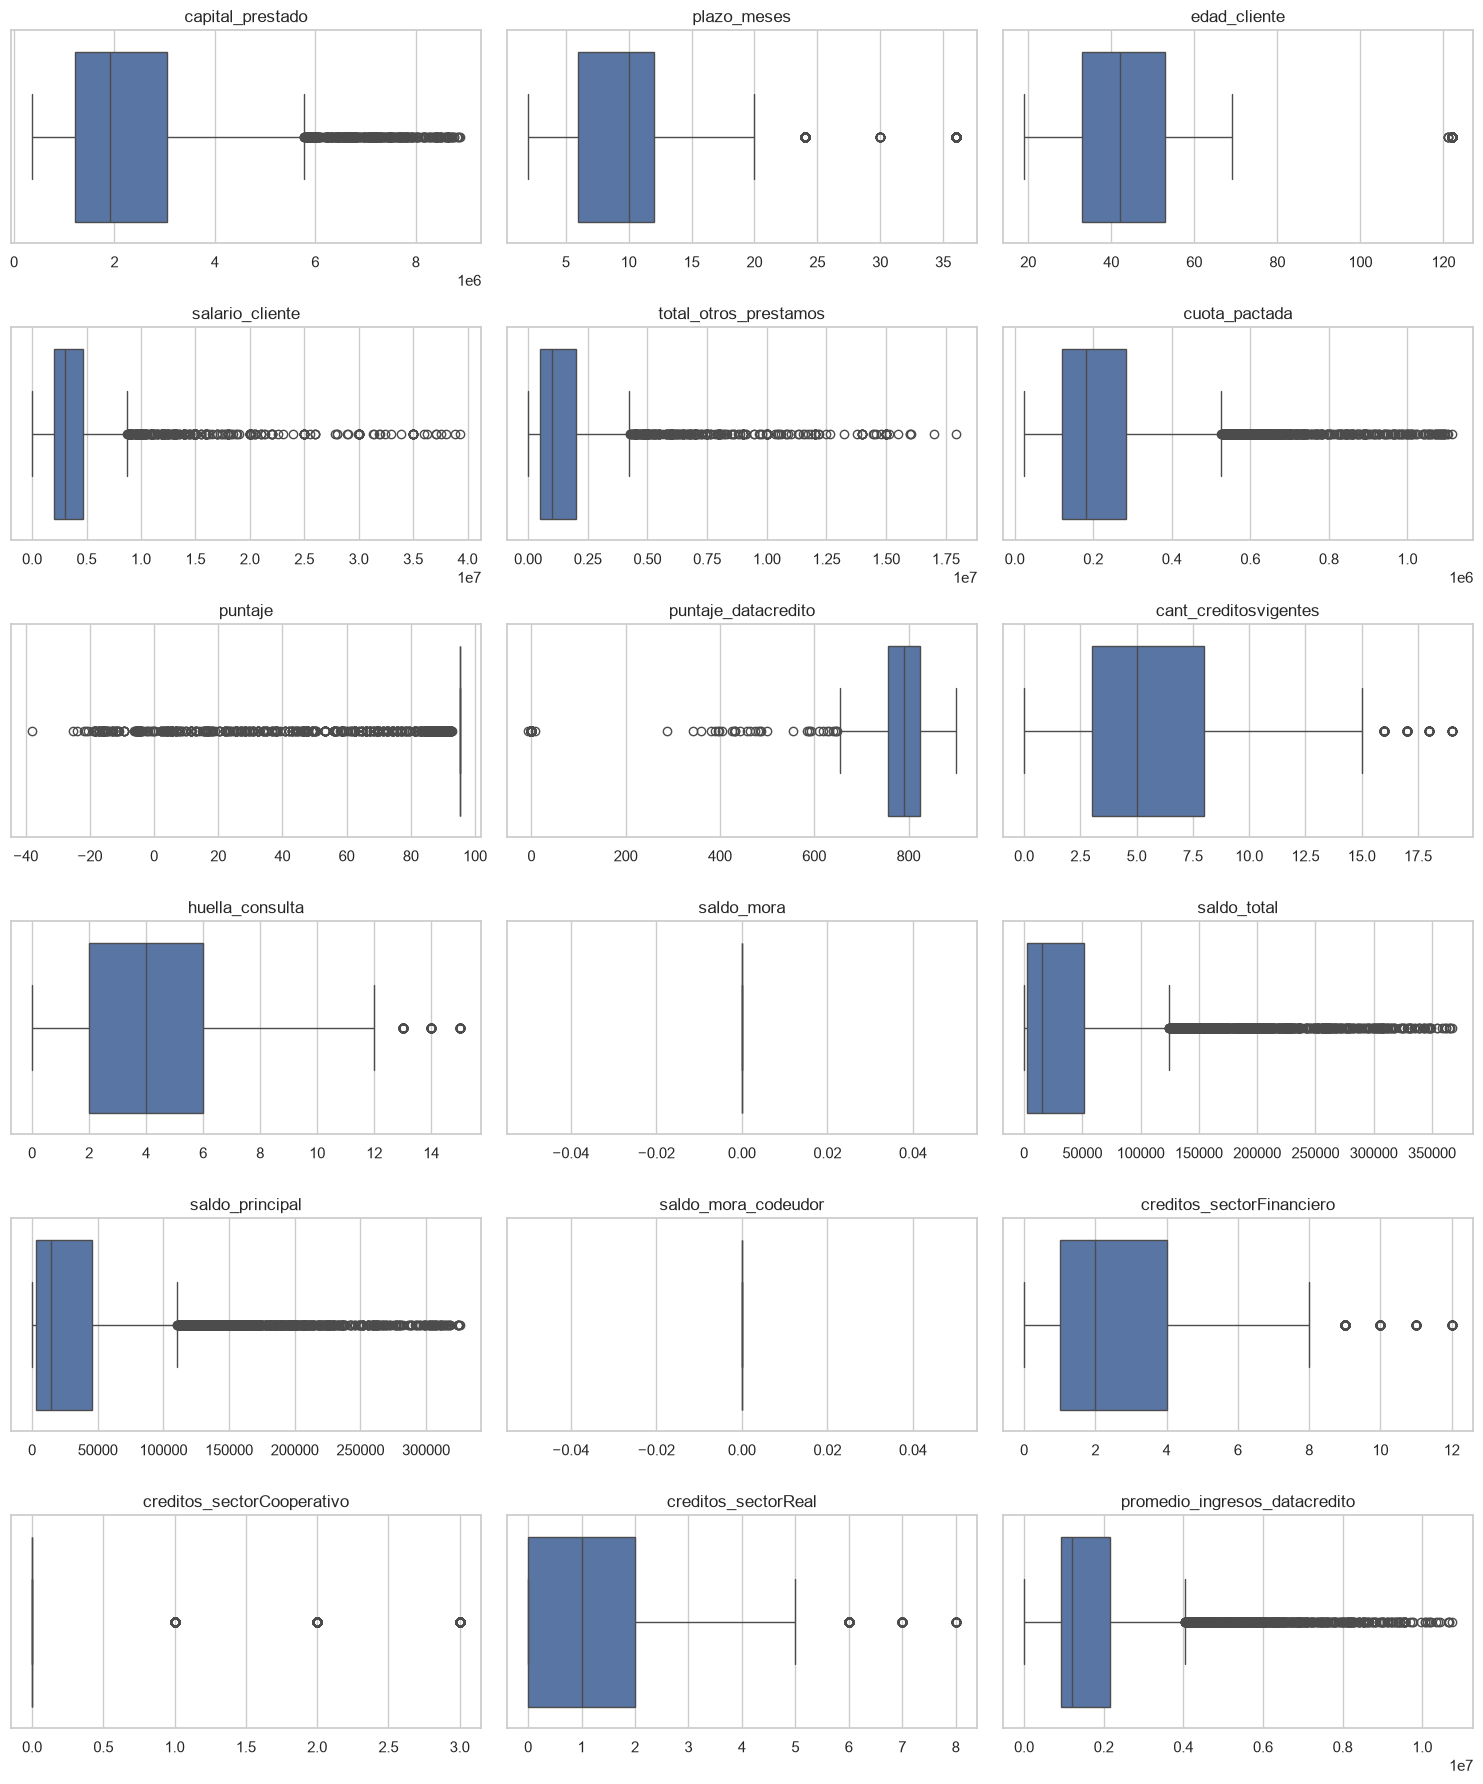

In [26]:
fig, axes = plt.subplots(6, 3, figsize=(15, 18))
for ax, col in zip(axes.flat, columnas_numericas):
    serie = df[col].dropna()
    limite = serie.quantile(0.99)
    sns.boxplot(x=serie[serie <= limite], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Cuántos valores atípicos hay en cada variable según la regla del IQR (sin recortar). Un valor atípico no es necesariamente un error: hay que distinguir los extremos legítimos de los errores.

In [27]:
limite_inf = q1 - 1.5 * (q3 - q1)
limite_sup = q3 + 1.5 * (q3 - q1)
atipicos = ((num < limite_inf) | (num > limite_sup)).sum()

pd.DataFrame({"atipicos": atipicos, "porcentaje": atipicos / num.notna().sum() * 100}).sort_values("atipicos", ascending=False)

,atipicos,porcentaje
creditos_sectorCooperativo,1895,17.61
puntaje,1356,12.60
saldo_total,970,9.14
saldo_principal,951,9.18
plazo_meses,869,8.07
promedio_ingresos_datacredito,784,10.01
cuota_pactada,765,7.11
salario_cliente,718,6.67
total_otros_prestamos,589,5.47
capital_prestado,550,5.11


### Tipo de distribución

Para decidir si una variable se parece a una distribución logarítmica (log-normal) se compara su asimetría antes y después de aplicar `log(1 + x)`. Si la asimetría baja cerca de 0, la variable es aproximadamente log-normal.

In [28]:
comparacion = pd.DataFrame(
    {
        "skew": num.skew(),
        "skew_despues_de_log": np.log1p(num.clip(lower=0)).skew(),
    }
)
comparacion

,skew,skew_despues_de_log
capital_prestado,3.72,0.11
plazo_meses,2.46,0.57
edad_cliente,1.93,0.31
salario_cliente,43.78,-4.89
total_otros_prestamos,38.46,-3.61
cuota_pactada,3.79,0.40
puntaje,-4.87,-6.80
puntaje_datacredito,-5.64,-8.29
cant_creditosvigentes,1.80,-0.63
huella_consulta,1.49,-0.52


**Lectura de las distribuciones** (a partir de los estadísticos y gráficos de arriba; es una lectura inicial, para revisar):

| Variable | Forma |
|---|---|
| `capital_prestado`, `cuota_pactada` | Asimétricas a la derecha (3.7 y 3.8). Tras el logaritmo la asimetría baja a 0.1 y 0.4: se parecen a una log-normal. |
| `edad_cliente` | La asimetría de 1.9 se debe al código 122. Sin él baja a 0.27 y la edad va de 19 a 69 años: aproximadamente simétrica, parecida a una gaussiana. |
| `salario_cliente`, `total_otros_prestamos` | Log-normales en el centro, pero con extremos a ambos lados (ceros y valores de miles de millones). El logaritmo no las normaliza (-4.9 y -3.6). |
| `promedio_ingresos_datacredito` | Asimétrica a la derecha (4.3). El logaritmo sobrecorrige (-3.5) por los valores cercanos a 0. |
| `plazo_meses` | Discreta, concentrada en pocos plazos (el 30.9% de las filas tiene 6 meses). |
| `cant_creditosvigentes`, `huella_consulta`, `creditos_sectorFinanciero`, `creditos_sectorReal` | Conteos con cola a la derecha: la forma típica de una variable de conteo. |
| `creditos_sectorCooperativo` | Conteo con 82.4% de ceros. |
| `saldo_total`, `saldo_principal` | Asimétricas a la derecha, con una masa de ceros (7.4% y 6.1%). |
| `puntaje_datacredito` | Asimetría negativa (-5.6) por los 146 valores en 0 o negativos. Sin los ceros baja a -1.0 y se concentra entre 757 y 825 (Q1 y Q3). |
| `puntaje` | Dominada por un solo valor (87.4%). No sigue ninguna distribución conocida. |
| `saldo_mora`, `saldo_mora_codeudor` | Casi constantes (99.5% y 100% en 0): no hay distribución que describir. |

### Edad sin recortar

El gráfico general corta en el percentil 99, así que aquí se ve la edad completa, con el bloque de 121 a 123 años.

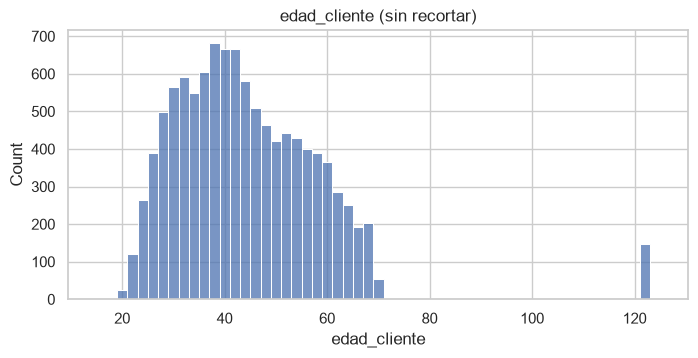

,filas
edad_cliente,
122,144
121,4
123,2


In [29]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(df["edad_cliente"], bins=range(15, 126, 2), ax=ax)
ax.set_title("edad_cliente (sin recortar)")
plt.show()

df.loc[df["edad_cliente"] > 100, "edad_cliente"].value_counts().to_frame("filas")

### Salario y otros préstamos en escala logarítmica

En una escala logarítmica cada marca vale 10 veces la anterior. Así se ven a la vez los valores normales y los extremos. Solo se incluyen valores mayores que 0, porque el logaritmo de 0 no existe.

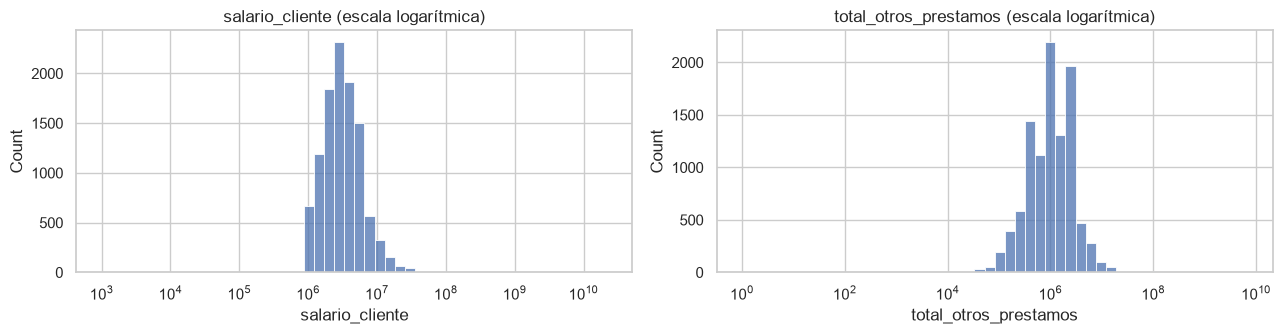

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, col in zip(axes, ["salario_cliente", "total_otros_prestamos"]):
    sns.histplot(df.loc[df[col] > 0, col], log_scale=True, bins=50, ax=ax)
    ax.set_title(f"{col} (escala logarítmica)")
plt.tight_layout()
plt.show()

In [31]:
cortes = [1e6, 1e7, 1e8, 1e9]
pd.DataFrame(
    {
        "salario_cliente": [(df["salario_cliente"] > c).sum() for c in cortes],
        "total_otros_prestamos": [(df["total_otros_prestamos"] > c).sum() for c in cortes],
    },
    index=[f"> {c:,.0f}" for c in cortes],
)

,salario_cliente,total_otros_prestamos
"> 1,000,000",10415,4766
"> 10,000,000",527,167
"> 100,000,000",74,44
"> 1,000,000,000",22,13


## 2.4 Variables categóricas

### Tipo laboral

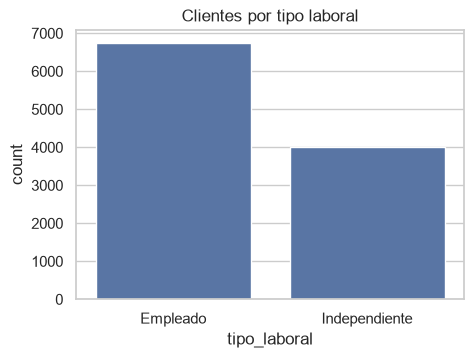

,porcentaje
tipo_laboral,
Empleado,62.75
Independiente,37.25


In [32]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="tipo_laboral", ax=ax)
ax.set_title("Clientes por tipo laboral")
plt.show()

df["tipo_laboral"].value_counts(normalize=True).mul(100).to_frame("porcentaje")

Una **tabla pivote** resume una variable numérica según las categorías de otra. Aquí, mediana del salario, del capital prestado y de la edad según el tipo laboral.

In [33]:
pd.pivot_table(
    df,
    index="tipo_laboral",
    values=["salario_cliente", "capital_prestado", "edad_cliente"],
    aggfunc=["count", "median"],
    observed=True,
)

count                                        median  \
              capital_prestado edad_cliente salario_cliente capital_prestado   
tipo_laboral                                                                   
Empleado                  6754         6754            6754     1,951,365.00   
Independiente             4009         4009            4009     1,872,000.00   

                                            
              edad_cliente salario_cliente  
tipo_laboral                                
Empleado             40.00    2,700,000.00  
Independiente        45.00    3,800,000.00

### Tendencia de ingresos

Los nulos se muestran como una categoría aparte (`Nulo`) para ver cuánto pesan frente a las categorías válidas.

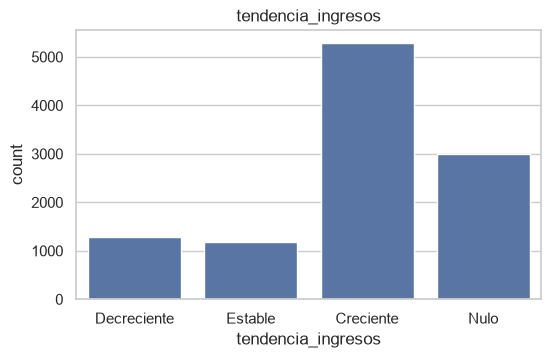

,filas
tendencia_ingresos,
Creciente,5294
Nulo,2990
Decreciente,1291
Estable,1188


In [34]:
tendencia = df["tendencia_ingresos"].astype("object").fillna("Nulo")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(x=tendencia, order=orden_tendencia + ["Nulo"], ax=ax)
ax.set_title("tendencia_ingresos")
plt.show()

tendencia.value_counts().to_frame("filas")

### Tipo de crédito

Aunque es un número, `tipo_credito` es un código de categoría.

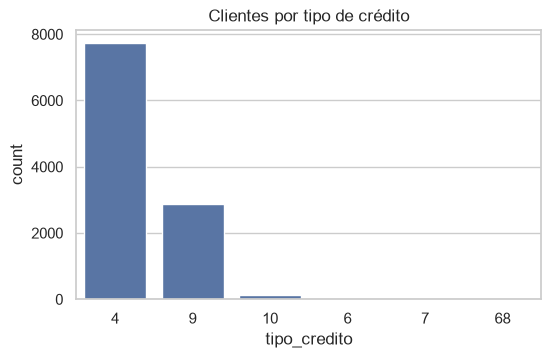

,filas,porcentaje
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.20
7,2,0.02
68,1,0.01


In [35]:
orden_credito = df["tipo_credito"].value_counts().index

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(data=df, x="tipo_credito", order=orden_credito, ax=ax)
ax.set_title("Clientes por tipo de crédito")
plt.show()

frecuencias = df["tipo_credito"].value_counts().to_frame("filas")
frecuencias["porcentaje"] = frecuencias["filas"] / len(df) * 100
frecuencias

## 2.5 Fecha del préstamo

Cantidad de préstamos por mes. El primer y el último mes pueden estar incompletos.

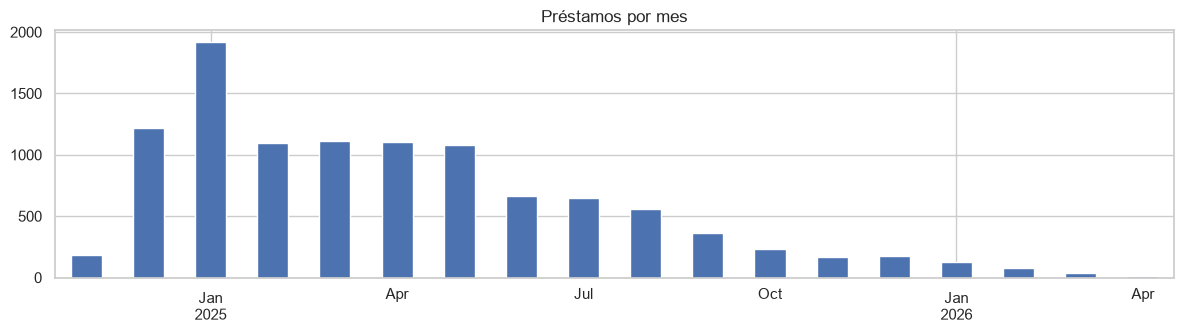

In [36]:
por_mes = df["fecha_prestamo"].dt.to_period("M").value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 3.5))
por_mes.plot(kind="bar", ax=ax)
ax.set_title("Préstamos por mes")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 2.6 Hallazgos del análisis univariable

- **Objetivo desbalanceado:** 95.3% pagó a tiempo y 4.7% no.
- **Variables monetarias:** `capital_prestado` y `cuota_pactada` se parecen a una log-normal. `salario_cliente` y `total_otros_prestamos` tienen extremos erróneos que distorsionan cualquier estadístico (la media del salario es 17.2 millones y la mediana 3 millones).
- **Casi constantes:** `saldo_mora_codeudor`, `saldo_mora` y `puntaje` aportan muy poca variación. Son candidatas a irrelevantes (1.8).
- **Códigos disfrazados:** la edad 122 y los puntajes 0, -7 y 999 parecen códigos. El profesor no los aclaró; se tratan como supuestos (5.4).
- **Tipo de crédito:** los códigos 4 y 9 concentran el 98.7% de las filas. Los demás (10, 6, 7 y 68) son muy pocos.
- **Tipo laboral:** 62.8% son empleados y 37.2% independientes.
- **Préstamos por mes:** el pico está en enero de 2025 (1,917 préstamos) y luego baja casi sin pausa hasta 11 préstamos en abril de 2026. Con tan pocos datos en los meses recientes, el monitoreo de drift del Avance 3 tendrá que tenerlo en cuenta.

# 3. Análisis bivariable

Se compara cada variable con la variable objetivo, `Pago_atiempo`. La pregunta es: ¿esta variable se comporta distinto en quienes pagaron a tiempo y en quienes no?

## 3.1 Variables numéricas frente al objetivo

Para cada variable se calculan dos cosas:

- La **mediana** en cada grupo (pagó a tiempo y no pagó). Se usa la mediana y no la media porque los extremos distorsionan la media.
- El **AUC univariado**: la probabilidad de que un cliente que pagó a tiempo tenga un valor más alto que uno que no pagó. Un AUC de 0.5 significa que la variable no distingue entre los dos grupos. Cerca de 1, los valores altos se asocian con pagar a tiempo. Cerca de 0, los valores altos se asocian con no pagar.

In [37]:
from sklearn.metrics import roc_auc_score

y = df[objetivo]
filas = []
for col in columnas_numericas:
    valido = df[col].notna()
    filas.append(
        {
            "variable": col,
            "mediana_pago": df.loc[(y == 1) & valido, col].median(),
            "mediana_no_pago": df.loc[(y == 0) & valido, col].median(),
            "auc": roc_auc_score(y[valido], df.loc[valido, col]),
        }
    )

bivariable_numericas = pd.DataFrame(filas).set_index("variable").sort_values("auc")
bivariable_numericas.style.format(
    {"mediana_pago": "{:,.1f}", "mediana_no_pago": "{:,.1f}", "auc": "{:.3f}"}
)

,mediana_pago,mediana_no_pago,auc
variable,,,
huella_consulta,4.0,5.0,0.402
capital_prestado,"1,908,446.4","2,268,000.0",0.443
creditos_sectorReal,1.0,1.0,0.476
plazo_meses,10.0,10.0,0.479
cuota_pactada,"182,576.0","199,002.0",0.480
saldo_mora,0.0,0.0,0.482
salario_cliente,"3,000,000.0","3,000,000.0",0.494
saldo_mora_codeudor,0.0,0.0,0.500
saldo_principal,"14,492.5","13,110.0",0.512


Distribución de cada variable según el grupo. Se muestran hasta el percentil 99, como en la sección 2.

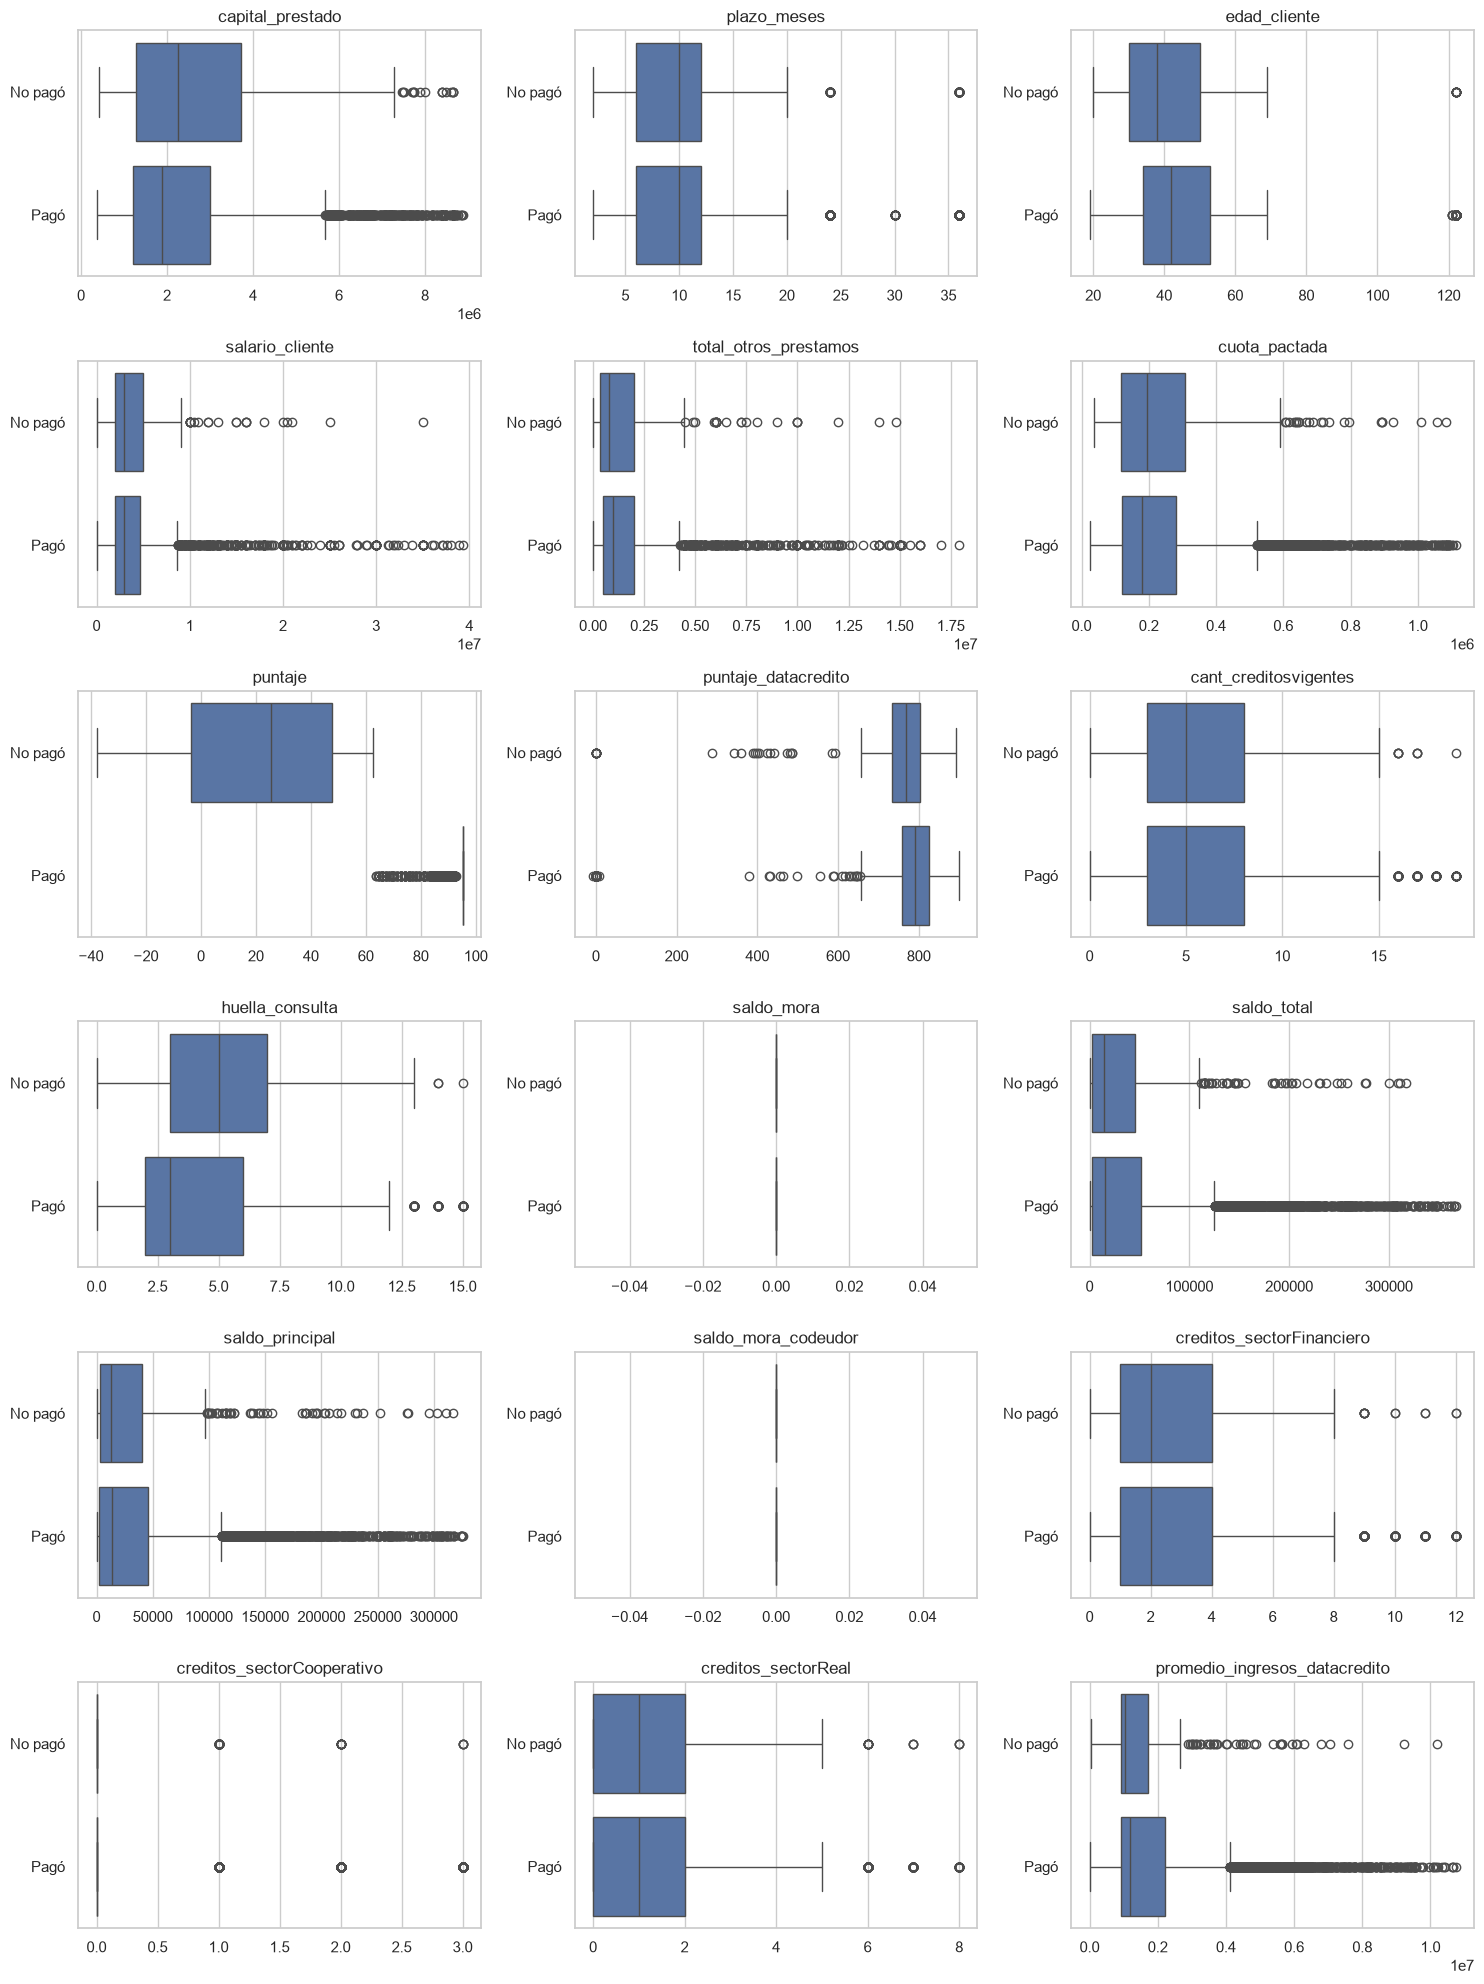

In [38]:
etiquetas = {0: "No pagó", 1: "Pagó"}

fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, col in zip(axes.flat, columnas_numericas):
    sub = df[[col, objetivo]].dropna()
    sub = sub[sub[col] <= sub[col].quantile(0.99)]
    sub = sub.assign(grupo=sub[objetivo].map(etiquetas))
    sns.boxplot(data=sub, x=col, y="grupo", order=["No pagó", "Pagó"], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

`puntaje_datacredito` por tramos, sin contar los valores 0 ni negativos (probables códigos). Los tramos son una elección nuestra.

In [39]:
tramos = pd.cut(
    df["puntaje_datacredito"],
    bins=[1, 500, 700, 900, 1001],
    right=False,
    labels=["1 a 499", "500 a 699", "700 a 899", "900 o más"],
)
df.groupby(tramos, observed=True)[objetivo].agg(filas="size", tasa_pago="mean").style.format(
    {"filas": "{:,.0f}", "tasa_pago": "{:.1%}"}
)

,filas,tasa_pago
puntaje_datacredito,,
1 a 499,21,33.3%
500 a 699,203,90.6%
700 a 899,"10,275",95.5%
900 o más,112,97.3%


**Lectura.**
- `puntaje` es el caso extremo (AUC = 1.0). Se analiza aparte en 3.2.
- **Ninguna de las demás distingue bien** a los dos grupos: su AUC va de 0.40 a 0.62.
- `huella_consulta` (0.40) es la relación más clara sin contar `puntaje`: quienes pagaron tienen una mediana de 4 consultas y quienes no, de 5. Más consultas se asocian con no pagar.
- `capital_prestado` (0.44): quienes no pagaron pidieron más (mediana de 2.27 millones frente a 1.91 millones).
- `puntaje_datacredito` (0.62): los puntajes más altos se asocian con pagar a tiempo, lo esperable. Por tramos la relación es más nítida: por debajo de 500 solo pagó a tiempo el 33.3% (21 filas); entre 500 y 699, el 90.6%; entre 700 y 899, el 95.5%; y con 900 o más, el 97.3%. El AUC de 0.62 subestima la relación porque los 145 ceros (probable código) se mezclan con los puntajes más bajos.
- `edad_cliente` y `promedio_ingresos_datacredito` (0.57 ambas): asociación positiva leve.
- `salario_cliente` (0.49) y `saldo_mora_codeudor` (0.50) no distinguen nada.

Un AUC cercano a 0.5 no significa que la variable sea inútil en un modelo: mide una variable sola, y varias variables débiles pueden aportar juntas. Pero sí anticipa que predecir este objetivo será difícil sin `puntaje`.

## 3.2 `puntaje` en detalle

En 1.7 vimos que el 87.4% de las filas repite un mismo valor y que todas pagaron a tiempo. Aquí se mira cómo se reparte el puntaje en cada grupo.

In [40]:
df.groupby(objetivo)["puntaje"].agg(filas="size", minimo="min", maximo="max", mediana="median")

,filas,minimo,maximo,mediana
Pago_atiempo,,,,
0,511,-38.01,62.67,25.42
1,10252,63.81,95.23,95.23


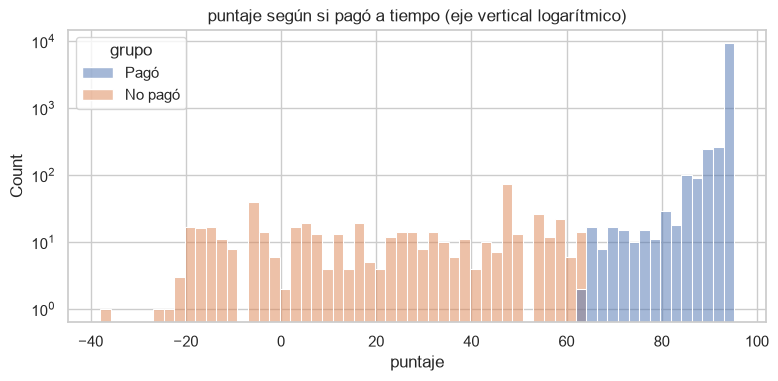

In [41]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(
    data=df.assign(grupo=df[objetivo].map(etiquetas)),
    x="puntaje",
    hue="grupo",
    bins=60,
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("puntaje según si pagó a tiempo (eje vertical logarítmico)")
plt.show()

In [42]:
print("Puntaje mínimo entre quienes pagaron:", round(df.loc[y == 1, "puntaje"].min(), 2))
print("Puntaje máximo entre quienes no pagaron:", round(df.loc[y == 0, "puntaje"].max(), 2))
print("AUC de puntaje:", round(roc_auc_score(y, df["puntaje"]), 3))

Puntaje mínimo entre quienes pagaron: 63.81
Puntaje máximo entre quienes no pagaron: 62.67
AUC de puntaje: 1.0


**Lectura.** Todos los clientes que no pagaron tienen un puntaje de 62.67 o menos, y todos los que pagaron tienen 63.81 o más. Un corte alrededor de 63 separa a los 10,763 clientes **sin un solo error**.

Las variables genuinas casi nunca separan tan bien. Esto tiene el aspecto de una variable calculada a partir del resultado (por ejemplo, un puntaje de comportamiento que se asigna después de saber si el cliente pagó). Si es así, un modelo que la use parecería perfecto al entrenar y fallaría en la práctica, porque cuando se decide un crédito todavía no se sabe si el cliente pagará. La otra posibilidad es que `Pago_atiempo` se haya definido a partir de `puntaje`. En cualquiera de los dos casos, **no sirve para predecir**.

Es una hipótesis, no una certeza: el diccionario del profesor no aclara qué es `puntaje`. Abajo se reúne más evidencia y se toma la decisión.

### Evidencia adicional y decisión

Además de la separación perfecta, se revisan tres señales: si el valor máximo funciona como un techo, si `puntaje` se relaciona con el historial crediticio previo del cliente y cómo cambia con la fecha del préstamo.

In [43]:
techo = df["puntaje"].max()
en_techo = df["puntaje"] == techo
print(f"Techo (valor máximo): {techo:.6f}")
print(f"Filas en el techo: {en_techo.sum():,} ({en_techo.mean():.1%}). Tasa de pago en ellas: {y[en_techo].mean():.1%}")

# Entre las filas que NO están en el techo: ¿se relaciona con el historial previo?
bajo_techo = df.loc[~en_techo]
print(f"\nFilas bajo el techo: {len(bajo_techo):,}. Correlación de puntaje con:")
print(bajo_techo[["puntaje_datacredito", "huella_consulta", "saldo_mora"]].corrwith(bajo_techo["puntaje"]).round(2).to_string())

# ¿Cambia la proporción en el techo según la fecha del préstamo?
en_techo.groupby(df["fecha_prestamo"].dt.to_period("Q")).agg(prop_en_techo="mean", filas="size").style.format(
    {"prop_en_techo": "{:.1%}", "filas": "{:,.0f}"}
)

Techo (valor máximo): 95.227787
Filas en el techo: 9,407 (87.4%). Tasa de pago en ellas: 100.0%

Filas bajo el techo: 1,356. Correlación de puntaje con:
puntaje_datacredito    0.10
huella_consulta       -0.15
saldo_mora            -0.14


,prop_en_techo,filas
fecha_prestamo,,
2024Q4,84.8%,"1,402"
2025Q1,85.7%,"4,126"
2025Q2,87.3%,"2,850"
2025Q3,90.7%,"1,560"
2025Q4,95.1%,571
2026Q1,93.0%,243
2026Q2,90.9%,11


**Lectura y decisión.**
- **Techo.** El máximo (95.227787) lo alcanza el 87.4% de las filas y todas pagaron a tiempo. Un score previo al crédito rara vez se satura así. Un puntaje de comportamiento, que se queda en el tope mientras no haya retrasos, sí.
- **No se explica con el historial previo.** Entre las 1,356 filas bajo el techo, la correlación de `puntaje` con `puntaje_datacredito` es 0.10, con `huella_consulta` -0.15 y con `saldo_mora` -0.14.
- **Sube con la recencia.** La proporción en el techo pasa de 84.8% (4.º trimestre de 2024) a 95.1% (4.º de 2025). Es coherente con un puntaje que se deteriora con el tiempo de exposición, pero no lo prueba: los trimestres recientes tienen pocas filas.

**Decisión (2026-11-10): `puntaje` se excluye del modelo.** Sea cual sea su origen (calculado con el comportamiento de pago de este crédito, o un score previo del que se derivó el objetivo), no sirve para predecir. No está demostrado que sea fuga: es una inferencia, y el diccionario del profesor no aclara qué es. El riesgo aceptado es doble: si fuera un score disponible antes del desembolso, se pierde el mejor predictor, y el modelo sin ella será modesto. En `model_training_evaluation.py` se entrenará una vez con `puntaje` y otra sin ella, para mostrar la diferencia en el `readme.md`.

## 3.3 Variables categóricas frente al objetivo

Tasa de pago a tiempo en cada categoría. Los nulos se muestran como una categoría aparte (`Nulo`).

In [44]:
def tasa_por_categoria(columna):
    serie = df[columna].astype("object").fillna("Nulo").astype(str)
    return df.groupby(serie)[objetivo].agg(filas="size", tasa_pago="mean")


tablas = {col: tasa_por_categoria(col) for col in columnas_categoricas}
tablas["tendencia_ingresos"] = tablas["tendencia_ingresos"].reindex(orden_tendencia + ["Nulo"])
tablas["tipo_credito"] = tablas["tipo_credito"].sort_values("filas", ascending=False)

pd.concat(tablas).style.format({"filas": "{:,.0f}", "tasa_pago": "{:.1%}"})

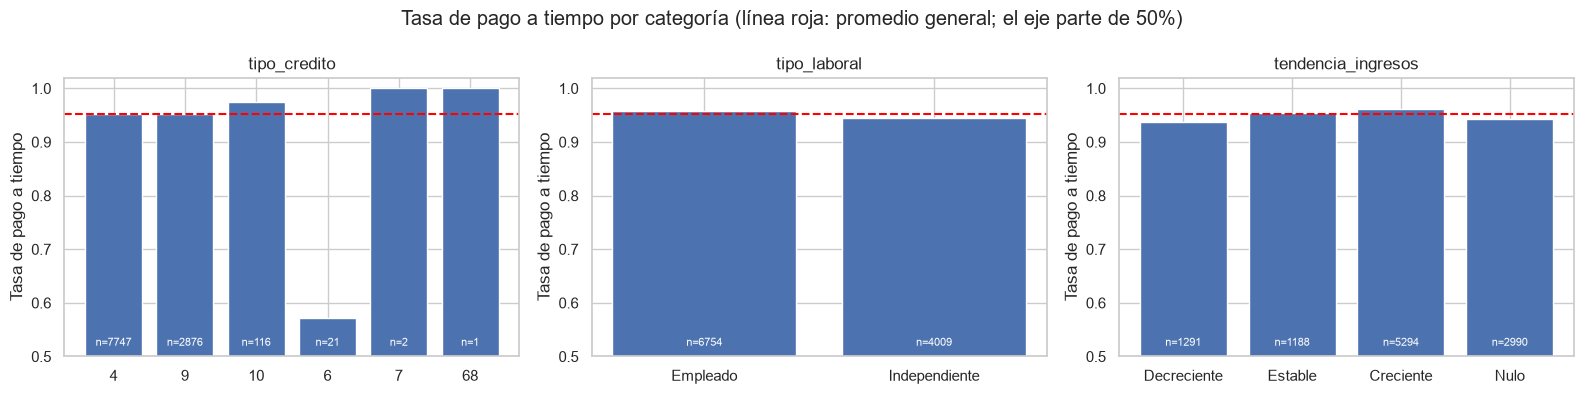

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, tabla) in zip(axes, tablas.items()):
    ax.bar(tabla.index, tabla["tasa_pago"])
    ax.axhline(y.mean(), color="red", linestyle="--")
    for i, filas_cat in enumerate(tabla["filas"]):
        ax.text(i, 0.52, f"n={filas_cat}", ha="center", color="white", fontsize=8)
    ax.set_ylim(0.5, 1.02)
    ax.set_title(col)
    ax.set_ylabel("Tasa de pago a tiempo")
fig.suptitle("Tasa de pago a tiempo por categoría (línea roja: promedio general; el eje parte de 50%)")
plt.tight_layout()
plt.show()

¿La diferencia entre categorías puede ser azar? La prueba de chi-cuadrado compara las tasas: un p-valor menor que 0.05 indica que la diferencia probablemente no es azar. Se aplica solo a las variables con categorías grandes.

In [46]:
from scipy.stats import chi2_contingency

pruebas = {}
for col in ["tipo_laboral", "tendencia_ingresos"]:
    serie = df[col].astype("object").fillna("Nulo").astype(str)
    pruebas[col] = chi2_contingency(pd.crosstab(serie, y))[1]

grandes = df[df["tipo_credito"].isin([4, 9, 10])]
pruebas["tipo_credito (solo códigos 4, 9 y 10)"] = chi2_contingency(
    pd.crosstab(grandes["tipo_credito"], grandes[objetivo])
)[1]

pd.Series(pruebas, name="p-valor").map("{:.4f}".format).to_frame()

,p-valor
tipo_laboral,0.0047
tendencia_ingresos,0.0002
"tipo_credito (solo códigos 4, 9 y 10)",0.5609


**Lectura.**
- `tipo_laboral`: empleados 95.7% e independientes 94.5%. La diferencia es pequeña pero no parece azar (p = 0.005). Tiene poco peso práctico.
- `tendencia_ingresos`: el orden es el esperable (Creciente 96.1%, Estable 95.4%, Decreciente 93.7%) y los nulos quedan cerca de 94%. La diferencia no parece azar (p = 0.0002).
- `tipo_credito`: los códigos 4, 9 y 10 están entre 95% y 97% y no se distinguen entre sí (p = 0.56). El código 6 tiene solo 21 filas y 57.1% de pago, pero con tan pocos casos no se puede concluir nada. Los códigos 7 y 68 tienen 2 y 1 filas.

## 3.4 Nulos y códigos raros frente al objetivo

Si los clientes con un dato faltante se comportan distinto, el nulo lleva información y conviene conservar un indicador.

In [47]:
columnas_con_nulos = resumen_nulos.index[resumen_nulos["nulos"] > 0]

nulos_vs_objetivo = pd.DataFrame(
    {
        col: {
            "filas_con_nulo": int(df[col].isna().sum()),
            "tasa_pago_con_dato": df.loc[df[col].notna(), objetivo].mean(),
            "tasa_pago_con_nulo": df.loc[df[col].isna(), objetivo].mean(),
        }
        for col in columnas_con_nulos
    }
).T
nulos_vs_objetivo.style.format(
    {"filas_con_nulo": "{:,.0f}", "tasa_pago_con_dato": "{:.1%}", "tasa_pago_con_nulo": "{:.1%}"}
)

,filas_con_nulo,tasa_pago_con_dato,tasa_pago_con_nulo
puntaje_datacredito,6,95.3%,83.3%
saldo_mora,156,95.3%,92.9%
saldo_total,156,95.3%,92.9%
saldo_principal,405,95.3%,92.8%
saldo_mora_codeudor,590,95.4%,93.2%
promedio_ingresos_datacredito,"2,930",95.6%,94.3%
tendencia_ingresos,"2,990",95.6%,94.4%


In [48]:
def resumen_grupos(grupos):
    tabla = pd.DataFrame(
        {nombre: {"filas": int(m.sum()), "tasa_pago": y[m].mean()} for nombre, m in grupos.items()}
    ).T
    return tabla.style.format({"filas": "{:,.0f}", "tasa_pago": "{:.1%}"})


print(f"Tasa de pago general: {y.mean():.1%}")
resumen_grupos(
    {
        "edad_cliente entre 121 y 123": df["edad_cliente"].between(121, 123),
        "puntaje_datacredito == 0": df["puntaje_datacredito"] == 0,
        "salario_cliente == 0": df["salario_cliente"] == 0,
        "salario_cliente > 100 millones": df["salario_cliente"] > 100_000_000,
        "total_otros_prestamos > 100 millones": df["total_otros_prestamos"] > 100_000_000,
        "promedio_ingresos_datacredito == 908,526": df["promedio_ingresos_datacredito"] == 908526,
    }
)

Tasa de pago general: 95.3%


,filas,tasa_pago
edad_cliente entre 121 y 123,150,92.7%
puntaje_datacredito == 0,145,93.1%
salario_cliente == 0,24,95.8%
salario_cliente > 100 millones,74,93.2%
total_otros_prestamos > 100 millones,44,95.5%
"promedio_ingresos_datacredito == 908,526",448,96.0%


**Lectura.**
- Los clientes con nulos pagan algo menos que el resto. Por ejemplo: `promedio_ingresos_datacredito` 94.3% con nulo frente a 95.6% con dato, y `saldo_principal` 92.8% frente a 95.3%. Las diferencias son pequeñas, pero sugieren que el nulo lleva algo de información. Por eso, en el Avance 2 conviene agregar un indicador de nulo en vez de rellenar sin dejar rastro.
- Los grupos de códigos raros (edad 121 a 123, `puntaje_datacredito` en 0, salarios gigantes) pagan entre 92.7% y 93.2%, algo por debajo del 95.3% general. Son grupos pequeños y no se puede afirmar mucho.
- Las 448 filas con `promedio_ingresos_datacredito` igual a 908,526 pagan 96.0%: no se distinguen del resto.

## 3.5 Candidatas a irrelevantes frente al objetivo

Con la relación con el objetivo a la vista, volvemos a las candidatas marcadas en 1.8.

In [49]:
resumen_grupos(
    {
        "saldo_mora > 0": df["saldo_mora"] > 0,
        "saldo_mora == 0": df["saldo_mora"] == 0,
        "saldo_mora_codeudor > 0": df["saldo_mora_codeudor"] > 0,
        "saldo_mora_codeudor == 0": df["saldo_mora_codeudor"] == 0,
    }
)

,filas,tasa_pago
saldo_mora > 0,55,63.6%
saldo_mora == 0,"10,552",95.5%
saldo_mora_codeudor > 0,3,100.0%
saldo_mora_codeudor == 0,"10,170",95.4%


**Lectura.**
- **`saldo_mora` no es irrelevante.** Aunque el 99.5% de las filas tiene 0, las 55 con saldo en mora pagan a tiempo solo el 63.6%, frente al 95.5% de las demás. Es la variable con mayor correlación con el objetivo después de `puntaje` (-0.11, ver 4.1). Su AUC (0.48) engaña porque son solo 55 filas. Una variable casi constante puede ser muy informativa en los pocos casos en que cambia. Propuesta: conservarla, o convertirla en un indicador `tiene_mora`.
- **`saldo_mora_codeudor`** tiene solo 3 filas distintas de 0 y las tres pagaron a tiempo. No aporta nada comprobable. Sigue como candidata a eliminar.
- **`puntaje`**: se excluye por riesgo de fuga (3.2), no por irrelevante.

## 3.6 Tasa de pago en el tiempo

Tasa de pago a tiempo según el trimestre del préstamo.

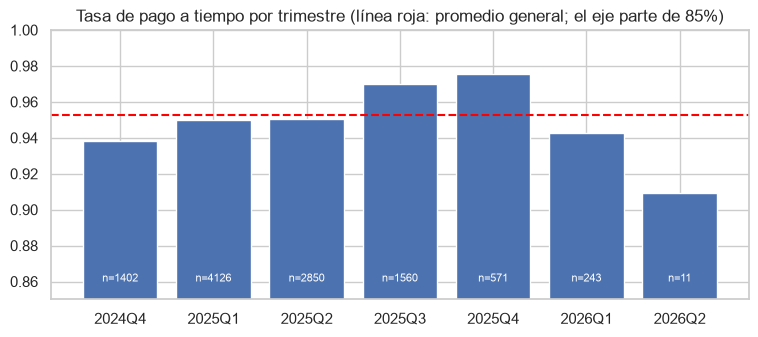

,filas,tasa_pago
fecha_prestamo,,
2024Q4,"1,402",93.8%
2025Q1,"4,126",95.0%
2025Q2,"2,850",95.1%
2025Q3,"1,560",97.0%
2025Q4,571,97.5%
2026Q1,243,94.2%
2026Q2,11,90.9%


In [50]:
por_trimestre = df.groupby(df["fecha_prestamo"].dt.to_period("Q"))[objetivo].agg(
    filas="size", tasa_pago="mean"
)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(por_trimestre.index.astype(str), por_trimestre["tasa_pago"])
ax.axhline(y.mean(), color="red", linestyle="--")
for i, filas_t in enumerate(por_trimestre["filas"]):
    ax.text(i, 0.86, f"n={filas_t}", ha="center", color="white", fontsize=8)
ax.set_ylim(0.85, 1.0)
ax.set_title("Tasa de pago a tiempo por trimestre (línea roja: promedio general; el eje parte de 85%)")
plt.show()

por_trimestre.style.format({"filas": "{:,.0f}", "tasa_pago": "{:.1%}"})

**Lectura.** La tasa va de 93.8% (último trimestre de 2024) a 97.5% (último de 2025) y baja a 94.2% en el primero de 2026. No hay un salto hacia 100% en los meses recientes, que sería lo esperable si los préstamos nuevos aún no hubieran vencido. Eso no lo descarta: los últimos trimestres tienen pocas filas (243 y 11). La duda sobre cómo se define `Pago_atiempo` sigue pendiente.

## 3.7 Hallazgos del análisis bivariable

- **`puntaje` separa perfectamente a los dos grupos** (corte en 63). Probable fuga de información. Se excluye del modelo (ver 3.2 y 5.4).
- **Sin `puntaje`, ninguna variable numérica distingue bien** entre quienes pagan y quienes no (AUC entre 0.40 y 0.62). Las más útiles: `huella_consulta`, `puntaje_datacredito`, `capital_prestado`, `edad_cliente` y `promedio_ingresos_datacredito`.
- **Categóricas:** `tipo_laboral` y `tendencia_ingresos` tienen diferencias pequeñas pero reales. `tipo_credito` no distingue entre sus códigos grandes.
- **Los nulos llevan algo de información:** conviene conservar indicadores de nulo.
- **`saldo_mora` es casi constante pero informativa** (63.6% de pago en las 55 filas con mora). `saldo_mora_codeudor` no lo es.
- **El problema será difícil:** con un 4.7% de casos negativos y señales débiles, las métricas deben ser recall, F1 y ROC-AUC, y no la exactitud.

# 4. Análisis multivariable

Se revisan las relaciones entre variables, para detectar redundancias y combinaciones que valga la pena usar.

## 4.1 Matriz de correlación

Se usa la correlación de **Spearman** y no la de Pearson. Spearman trabaja con el orden de los valores y no con los valores mismos, así que los extremos (salarios de miles de millones) no la distorsionan. Va de -1 a 1; cerca de 0 significa que no hay relación monótona.

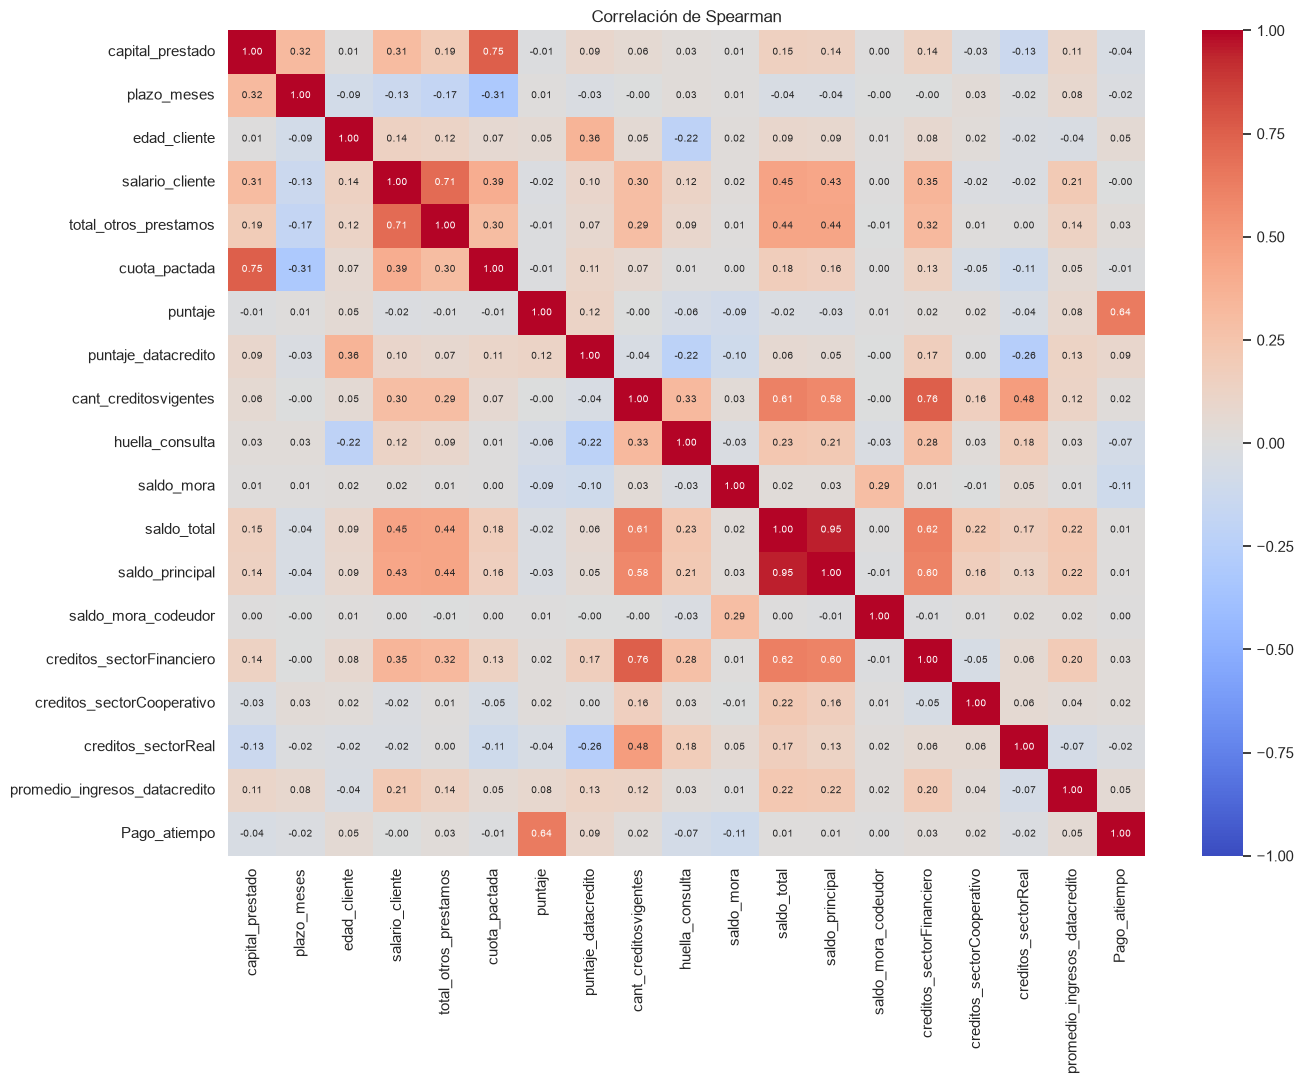

In [51]:
correlacion = df[columnas_numericas + [objetivo]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax,
)
ax.set_title("Correlación de Spearman")
plt.tight_layout()
plt.show()

## 4.2 Pares muy correlacionados

Pares de variables con una correlación (en valor absoluto) de 0.6 o más.

In [52]:
triangulo = correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1)).stack()
pares_fuertes = triangulo[triangulo.abs() >= 0.6].sort_values(key=lambda s: s.abs(), ascending=False)
pares_fuertes.rename("spearman").to_frame()

,,spearman
saldo_total,saldo_principal,0.95
cant_creditosvigentes,creditos_sectorFinanciero,0.76
capital_prestado,cuota_pactada,0.75
salario_cliente,total_otros_prestamos,0.71
puntaje,Pago_atiempo,0.64
saldo_total,creditos_sectorFinanciero,0.62
cant_creditosvigentes,saldo_total,0.61
saldo_principal,creditos_sectorFinanciero,0.60


**Lectura.**
- `saldo_total` y `saldo_principal` (0.95) son casi la misma información. En un modelo lineal convendría dejar solo una.
- `cant_creditosvigentes` y `creditos_sectorFinanciero` (0.76): los créditos financieros son la mayor parte de los vigentes.
- `capital_prestado` y `cuota_pactada` (0.75): lógico, a más capital, más cuota.
- `salario_cliente` y `total_otros_prestamos` (0.71): quien gana más tiene más deuda.
- Con la variable objetivo, solo `puntaje` (0.64) tiene una correlación notable. Las demás van de -0.11 (`saldo_mora`) a 0.09 (`puntaje_datacredito`).

Los modelos de árboles (como XGBoost) toleran bien variables redundantes. Los modelos lineales no, y para ellos habría que quitar o combinar los pares de arriba.

## 4.3 Gráficos de dispersión

Cuatro de los pares más relacionados, con una muestra de 3,000 clientes y el color según si pagaron. Los montos van en escala logarítmica.

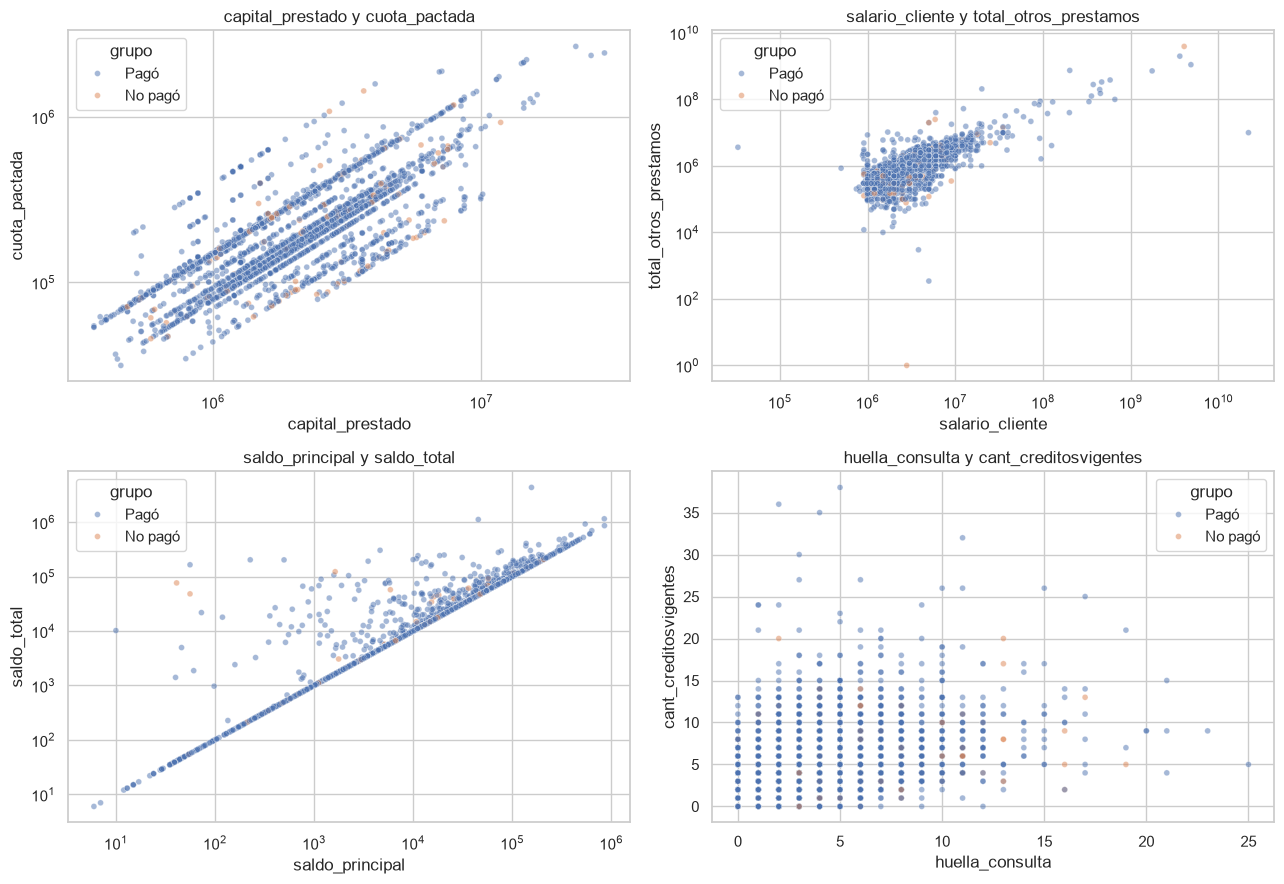

In [53]:
muestra = df.sample(3000, random_state=42).assign(grupo=lambda x: x[objetivo].map(etiquetas))

pares_dispersion = [
    ("capital_prestado", "cuota_pactada", True),
    ("salario_cliente", "total_otros_prestamos", True),
    ("saldo_principal", "saldo_total", True),
    ("huella_consulta", "cant_creditosvigentes", False),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (eje_x, eje_y, usa_log) in zip(axes.flat, pares_dispersion):
    sns.scatterplot(
        data=muestra, x=eje_x, y=eje_y, hue="grupo",
        hue_order=["Pagó", "No pagó"], alpha=0.5, s=18, ax=ax,
    )
    if usa_log:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_title(f"{eje_x} y {eje_y}")
plt.tight_layout()
plt.show()

## 4.4 Pairplot

Relaciones de a pares entre cinco variables, con el color según el grupo. Para que los extremos y los códigos raros no aplasten los gráficos, se excluyen la edad 122, los puntajes de Datacrédito en 0 y el 1% más alto de capital y cuota. Es una muestra de 1,500 clientes.

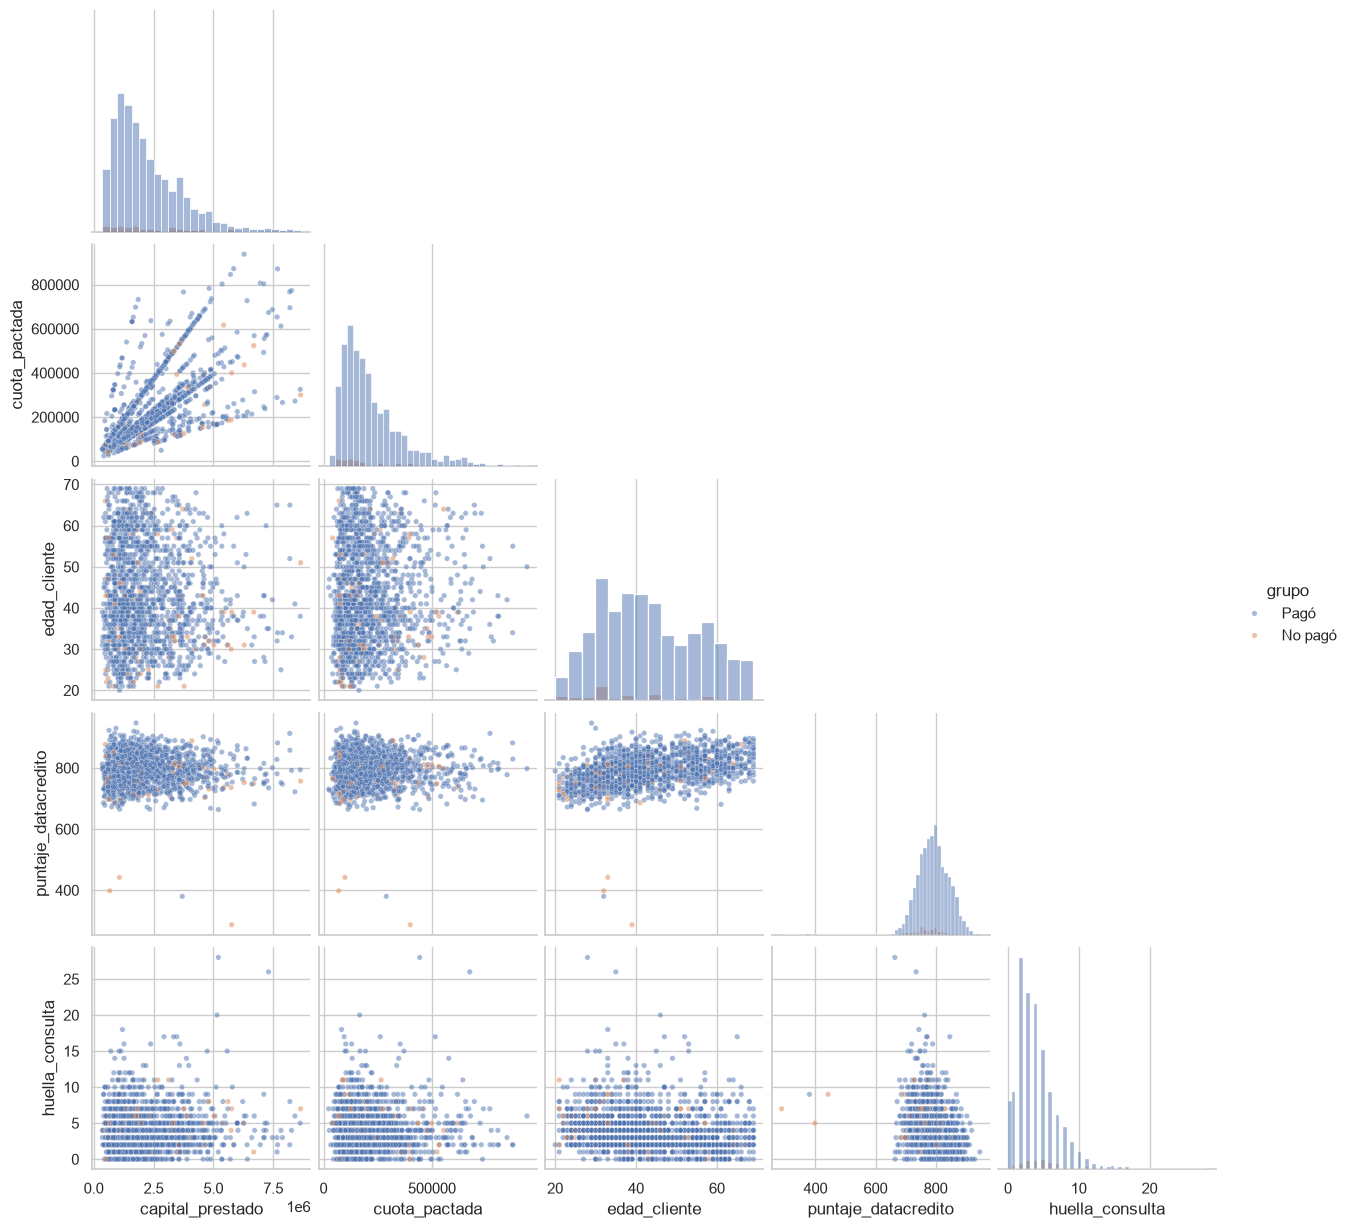

In [54]:
variables_pairplot = ["capital_prestado", "cuota_pactada", "edad_cliente", "puntaje_datacredito", "huella_consulta"]

sub = df[variables_pairplot + [objetivo]].dropna()
sub = sub[(sub["edad_cliente"] < 100) & (sub["puntaje_datacredito"] > 0)]
for col in ["capital_prestado", "cuota_pactada"]:
    sub = sub[sub[col] <= sub[col].quantile(0.99)]
sub = sub.sample(1500, random_state=42).assign(grupo=lambda x: x[objetivo].map(etiquetas))

sns.pairplot(
    sub.drop(columns=objetivo), hue="grupo", hue_order=["Pagó", "No pagó"],
    corner=True, diag_kind="hist", plot_kws={"alpha": 0.5, "s": 15},
)
plt.show()

**Lectura de 4.3 y 4.4.**
- Capital y cuota (y salario y otros préstamos) muestran una relación creciente, como indicaba la correlación. Entre capital y cuota se ven **franjas diagonales paralelas**: dentro de cada plazo la cuota es casi una fracción fija del capital (ver 5.1).
- `saldo_principal` y `saldo_total` quedan pegados a la diagonal: en el 80.4% de las filas son iguales. En el resto el total es mayor (probablemente incluye intereses o mora, por confirmar).
- Los clientes que no pagaron (el grupo minoritario) quedan **mezclados con el resto en casi todos los gráficos**. Ninguna combinación de dos variables los separa de forma clara, coherente con los AUC bajos de 3.1. La excepción son los puntajes de Datacrédito muy bajos (por debajo de 500), donde se concentran varios de los clientes que no pagaron (ver el tramo de 3.1).

## 4.5 Variables categóricas entre sí

In [55]:
tendencia_texto = df["tendencia_ingresos"].astype("object").fillna("Nulo")

pd.crosstab(df["tipo_laboral"], tendencia_texto, normalize="index").mul(100)[orden_tendencia + ["Nulo"]].round(1)

tendencia_ingresos,Decreciente,Estable,Creciente,Nulo
tipo_laboral,,,,
Empleado,13.90,9.60,56.90,19.70
Independiente,8.80,13.50,36.20,41.50


In [56]:
pd.crosstab(df["tipo_credito"], df["tipo_laboral"])

tipo_laboral,Empleado,Independiente
tipo_credito,,
4,5052,2695
6,21,0
7,1,1
9,1604,1272
10,75,41
68,1,0


**Lectura.**
- **Los independientes tienen muchos más nulos en `tendencia_ingresos`** (41.5% frente a 19.7% de los empleados) y menos casos de tendencia creciente (36.2% frente a 56.9%). Es coherente con la idea de que los independientes tienen menos historial de ingresos reportado, pero es una hipótesis.
- `tipo_credito`: los códigos 6 y 68 son solo de empleados; el resto tiene mezcla de ambos tipos laborales. Son muy pocos casos para sacar conclusiones.

## 4.6 Gráficos con una variable categórica como color

Izquierda: salario y capital prestado según el tipo laboral. Derecha: capital prestado según el tipo de crédito (hasta el percentil 99).

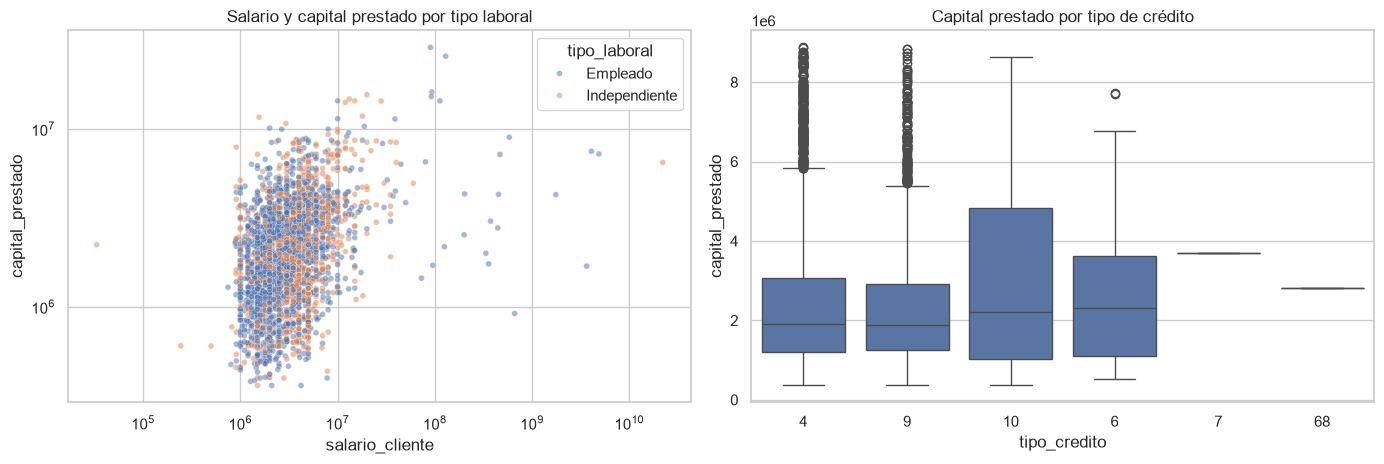

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.scatterplot(
    data=muestra, x="salario_cliente", y="capital_prestado", hue="tipo_laboral",
    alpha=0.5, s=18, ax=axes[0],
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Salario y capital prestado por tipo laboral")

p99 = df["capital_prestado"].quantile(0.99)
sns.boxplot(
    data=df[df["capital_prestado"] <= p99], x="tipo_credito", y="capital_prestado",
    order=df["tipo_credito"].value_counts().index, ax=axes[1],
)
axes[1].set_title("Capital prestado por tipo de crédito")
plt.tight_layout()
plt.show()

**Lectura.**
- Salario y capital prestado tienen una relación débil (Spearman 0.31): el monto que se pide no depende mucho del salario declarado. Los dos tipos laborales se mezclan.
- Los créditos tipo 4 y 9 tienen montos parecidos (medianas de 1.93 y 1.89 millones). Los códigos 6, 7, 10 y 68 tienen pocos casos y montos algo mayores, pero sin muestra suficiente para afirmarlo.

## 4.7 Hallazgos del análisis multivariable

- **Redundancia:** `saldo_total` y `saldo_principal` (0.95) casi duplican la información. También hay relación entre `capital_prestado` y `cuota_pactada` (0.75), y entre `cant_creditosvigentes` y `creditos_sectorFinanciero` (0.76).
- **Ningún par de variables separa bien** a quienes no pagaron: señal débil también en combinaciones.
- **Los independientes tienen más nulos en ingresos** que los empleados: el nulo no está distribuido al azar.

# 5. Conclusiones

Lo que la exploración deja para las etapas siguientes: reglas de validación de datos, transformaciones que se podrían aplicar y atributos derivados.

## 5.1 Reglas de validación de datos

Reglas que cada registro nuevo debería cumplir. Se aplican a la base **original** (`df_original`) para contar cuántas filas las incumplen.

- **Firme:** la regla es lógica y no depende de un umbral (un saldo no puede ser negativo).
- **Provisional:** el umbral es una elección razonable, no un dato; es criterio propio y queda documentado en 5.4.

In [58]:
hoy = pd.Timestamp.today()
origen = df_original


def al_menos_cero(col):
    return lambda x: (x[col] >= 0) | x[col].isna()


reglas = [
    ("edad_cliente entre 18 y 100", lambda x: x["edad_cliente"].between(18, 100), "Provisional", "Hay 150 filas con 121 a 123 años (probable código)"),
    ("salario_cliente > 0", lambda x: x["salario_cliente"] > 0, "Provisional", "El 0 podría significar sin ingreso declarado"),
    ("salario_cliente <= 100 millones", lambda x: x["salario_cliente"] <= 100_000_000, "Provisional", "Hay salarios de hasta 22,000 millones"),
    ("total_otros_prestamos >= 0", al_menos_cero("total_otros_prestamos"), "Firme", "Un monto no puede ser negativo"),
    ("total_otros_prestamos <= 100 millones", lambda x: x["total_otros_prestamos"] <= 100_000_000, "Provisional", "Hay valores de hasta 6,787 millones"),
    ("capital_prestado > 0", lambda x: x["capital_prestado"] > 0, "Firme", "Un préstamo tiene un monto positivo"),
    ("cuota_pactada > 0", lambda x: x["cuota_pactada"] > 0, "Firme", "Una cuota es positiva"),
    ("plazo_meses entre 1 y 60", lambda x: x["plazo_meses"].between(1, 60), "Provisional", "Hay un plazo de 90 meses"),
    ("puntaje_datacredito >= 0", al_menos_cero("puntaje_datacredito"), "Provisional", "Hay un valor de -7; la escala es desconocida"),
    ("saldo_mora >= 0", al_menos_cero("saldo_mora"), "Firme", "Un saldo no puede ser negativo"),
    ("saldo_total >= 0", al_menos_cero("saldo_total"), "Firme", "Un saldo no puede ser negativo"),
    ("saldo_principal >= 0", al_menos_cero("saldo_principal"), "Firme", "Un saldo no puede ser negativo"),
    ("saldo_mora_codeudor >= 0", al_menos_cero("saldo_mora_codeudor"), "Firme", "Un saldo no puede ser negativo"),
    ("saldo_principal <= saldo_total", lambda x: (x["saldo_principal"] <= x["saldo_total"]) | x["saldo_principal"].isna() | x["saldo_total"].isna(), "Firme", "El capital no puede superar el total"),
    ("saldo_mora <= saldo_total", lambda x: (x["saldo_mora"] <= x["saldo_total"]) | x["saldo_mora"].isna() | x["saldo_total"].isna(), "Firme", "La mora no puede superar el total"),
    ("cant_creditosvigentes >= 0", al_menos_cero("cant_creditosvigentes"), "Firme", "Un conteo no puede ser negativo"),
    ("huella_consulta >= 0", al_menos_cero("huella_consulta"), "Firme", "Un conteo no puede ser negativo"),
    ("tipo_laboral es Empleado o Independiente", lambda x: x["tipo_laboral"].isin(["Empleado", "Independiente"]), "Firme", "Son las dos categorías observadas"),
    ("tendencia_ingresos es Creciente, Estable, Decreciente o nulo", lambda x: x["tendencia_ingresos"].isin(orden_tendencia) | x["tendencia_ingresos"].isna(), "Firme", "Hay 58 valores numéricos que no son categorías"),
    ("Pago_atiempo es 0 o 1", lambda x: x["Pago_atiempo"].isin([0, 1]), "Firme", "Variable dicotómica"),
    ("fecha_prestamo no es futura", lambda x: x["fecha_prestamo"] <= hoy, "Firme", "Un préstamo no puede ser posterior a hoy"),
]

validacion = pd.DataFrame(
    [
        {"regla": nombre, "estado": estado, "filas_que_no_cumplen": int((~funcion(origen)).sum()), "motivo": motivo}
        for nombre, funcion, estado, motivo in reglas
    ]
)
validacion

,regla,estado,filas_que_no_cumplen,motivo
0,edad_cliente entre 18 y 100,Provisional,150,Hay 150 filas con 121 a 123 años (probable cód...
1,salario_cliente > 0,Provisional,24,El 0 podría significar sin ingreso declarado
2,salario_cliente <= 100 millones,Provisional,74,"Hay salarios de hasta 22,000 millones"
3,total_otros_prestamos >= 0,Firme,0,Un monto no puede ser negativo
4,total_otros_prestamos <= 100 millones,Provisional,44,"Hay valores de hasta 6,787 millones"
5,capital_prestado > 0,Firme,0,Un préstamo tiene un monto positivo
6,cuota_pactada > 0,Firme,0,Una cuota es positiva
7,plazo_meses entre 1 y 60,Provisional,1,Hay un plazo de 90 meses
8,puntaje_datacredito >= 0,Provisional,1,Hay un valor de -7; la escala es desconocida
9,saldo_mora >= 0,Firme,0,Un saldo no puede ser negativo


Además de las reglas, hay **inconsistencias que aún no sabemos si son errores**. Se cuentan para dejarlas documentadas: el profesor no dará más información sobre las variables.

In [59]:
total_sectores = df[["creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal"]].sum(axis=1)

pd.Series(
    {
        "cuota_pactada x plazo_meses < capital_prestado": int((df["cuota_pactada"] * df["plazo_meses"] < df["capital_prestado"]).sum()),
        "suma de créditos por sector < cant_creditosvigentes": int((total_sectores < df["cant_creditosvigentes"]).sum()),
        "suma de créditos por sector > cant_creditosvigentes": int((total_sectores > df["cant_creditosvigentes"]).sum()),
    },
    name="filas",
).to_frame()

,filas
cuota_pactada x plazo_meses < capital_prestado,9784
suma de créditos por sector < cant_creditosvigentes,7642
suma de créditos por sector > cant_creditosvigentes,4


**Lectura.**
- Las reglas **firmes** se cumplen en casi todos los casos. El incumplimiento está en las **provisionales** (edad, salario, otros préstamos, plazo, puntaje de Datacrédito) y en `tendencia_ingresos`.
- En el 90.9% de las filas, `cuota_pactada` x `plazo_meses` es **menor** que `capital_prestado` (el cociente va de 0.79 a 1.52 y su mediana es 0.89). Si la cuota fuera mensual y el plazo estuviera en meses, con intereses se pagaría más que el capital, no menos. Dentro de cada plazo el cociente es casi constante (0.79 con 2 meses, 0.89 con 6, 0.94 con 12 y 1.0 con 18), por eso aparecen las franjas de 4.3. Es una relación sistemática y no un error aleatorio: la cuota parece calculada con una fórmula a partir del capital y el plazo, pero no sabemos cuál ni cada cuánto se paga. Queda como duda abierta, sin fuente para resolverla.
- En el 71% de las filas la suma de créditos por sector es menor que los créditos vigentes, y solo en 4 filas es mayor. Es coherente con que falten sectores en la base, no con un error.

## 5.2 Transformaciones aplicables

Propuestas para `ft_engineering.py` (Avance 2). Son una lista de ideas con su motivo, no decisiones tomadas.

| Variable o grupo | Transformación propuesta | Motivo |
|---|---|---|
| `capital_prestado`, `cuota_pactada` | Logaritmo `log(1 + x)` | La asimetría baja de 3.7 y 3.8 a 0.1 y 0.4 (sección 2.3) |
| `salario_cliente`, `total_otros_prestamos` | Marcar como nulo o limitar los valores por encima de un umbral, y luego aplicar logaritmo | Extremos erróneos de miles de millones |
| `promedio_ingresos_datacredito` | Logaritmo, más un indicador de nulo | Asimetría 4.3 y 27% de nulos |
| `edad_cliente` | Convertir 121 a 123 en nulo y agregar un indicador | Probable código de edad desconocida |
| `puntaje_datacredito` | Convertir 0 y -7 en nulo y agregar un indicador, (supuesto 4 de 5.4; el significado no está confirmado) | Probables códigos de "sin puntaje" |
| `tendencia_ingresos` | Codificación ordinal (Decreciente 0, Estable 1, Creciente 2) y una categoría aparte para los nulos | Variable ordinal; el nulo lleva información |
| `tipo_laboral` | Binaria (0 o 1) | Dicotómica |
| `tipo_credito` | Agrupar los códigos 6, 7, 10 y 68 en una categoría "otros" y luego codificar | Tienen muy pocas filas |
| `saldo_*` con nulos | Imputar y agregar un indicador de nulo. Evaluar si el nulo de `saldo_mora_codeudor` significa que no hay codeudor (0) | Los nulos se asocian con un pago algo menor |
| `saldo_total`, `saldo_principal` | Conservar una sola en modelos lineales | Correlación de 0.95 |
| `saldo_mora` | Convertir en indicador `tiene_mora` (además de conservarla) | Solo 55 filas distintas de 0, pero muy informativas |
| `puntaje` | **Excluir** del modelo (decisión en 3.2). En el Avance 2, entrenar una vez con ella solo para mostrar la fuga | Probable fuga de información |
| Variables numéricas, en modelos lineales | Estandarizar | Escalas muy distintas. Los modelos de árboles no lo necesitan |
| Objetivo | Partición estratificada, ponderación de clases y métricas recall, F1 y ROC-AUC | Solo 4.7% de casos negativos |

Una precaución para el Avance 2: toda imputación y todo escalado deben **ajustarse solo con los datos de entrenamiento** y aplicarse después a los de prueba. Si se calculan con toda la base, se filtra información de prueba al entrenamiento.

## 5.3 Atributos derivados

Variables nuevas que se podrían calcular a partir de las existentes. Para ver si alguna vale la pena, se mide su AUC frente al objetivo (como en 3.1). Los cocientes con el salario excluyen los salarios iguales a 0 o mayores que 100 millones.

In [60]:
salario_valido = df["salario_cliente"].where(
    (df["salario_cliente"] > 0) & (df["salario_cliente"] <= 100_000_000)
)
ingreso_valido = df["promedio_ingresos_datacredito"].where(df["promedio_ingresos_datacredito"] > 0)
saldo_total_valido = df["saldo_total"].where(df["saldo_total"] > 0)

derivadas = pd.DataFrame(
    {
        "cuota_sobre_salario": df["cuota_pactada"] / salario_valido,
        "capital_sobre_salario": df["capital_prestado"] / salario_valido,
        "otros_prestamos_sobre_salario": df["total_otros_prestamos"] / salario_valido,
        "cuota_sobre_ingreso_datacredito": df["cuota_pactada"] / ingreso_valido,
        "costo_relativo": df["cuota_pactada"] * df["plazo_meses"] / df["capital_prestado"],
        "proporcion_saldo_principal": df["saldo_principal"] / saldo_total_valido,
        "total_creditos_sectores": total_sectores,
        "tiene_mora": (df["saldo_mora"] > 0).astype(int),
        "sin_historial_ingresos": df["promedio_ingresos_datacredito"].isna().astype(int),
    }
)

filas = []
for col in derivadas:
    ok = derivadas[col].notna() & np.isfinite(derivadas[col])
    auc = roc_auc_score(y[ok], derivadas.loc[ok, col])
    filas.append({"atributo": col, "filas_validas": int(ok.sum()), "auc": auc, "distancia_a_0.5": abs(auc - 0.5)})

pd.DataFrame(filas).set_index("atributo").sort_values("distancia_a_0.5", ascending=False).style.format(
    {"filas_validas": "{:,.0f}", "auc": "{:.3f}", "distancia_a_0.5": "{:.3f}"}
)

,filas_validas,auc,distancia_a_0.5
atributo,,,
cuota_sobre_ingreso_datacredito,"7,826",0.439,0.061
otros_prestamos_sobre_salario,"10,665",0.547,0.047
capital_sobre_salario,"10,665",0.459,0.041
sin_historial_ingresos,"10,763",0.470,0.030
total_creditos_sectores,"10,763",0.527,0.027
tiene_mora,"10,763",0.482,0.018
cuota_sobre_salario,"10,665",0.489,0.011
proporcion_saldo_principal,"9,818",0.493,0.007
costo_relativo,"10,763",0.495,0.005


**Lectura.**
- Ningún atributo derivado supera a `huella_consulta` (AUC 0.40) en señal. El mejor es `cuota_sobre_ingreso_datacredito` (0.44), que además mejora a `cuota_pactada` sola (0.48): la carga de la cuota frente al ingreso reportado dice algo más que la cuota sola.
- `capital_sobre_salario` (0.46) y `otros_prestamos_sobre_salario` (0.55) aportan algo, aunque poco. El resto está muy cerca de 0.5.
- Una señal débil por separado no descarta un atributo: un modelo puede combinarlo con otros. Se pueden probar en el Avance 2 y conservar solo los que mejoren las métricas en datos de prueba.

## 5.4 Supuestos de trabajo

El diccionario del profesor es una interpretación y no la oficial (él mismo no está seguro de varios casos), así que varias decisiones se toman con criterio propio. Se listan aquí para que queden a la vista (y pasen al `readme.md`). Son **provisionales** y están sujetas a revisión.

| # | Supuesto | Por qué |
|---|---|---|
| 1 | La variable objetivo es `Pago_atiempo` (1 = pagó a tiempo). | Confirmada por el profesor. La dirección del 0 y el 1 viene de su diccionario ("probablemente"). Además, es la única columna de dos valores que describe un resultado del crédito (ver 1.2). |
| 2 | `puntaje` no se usa como variable del modelo (decisión del 2026-11-10). | Separa perfectamente el objetivo (corte en 63), tiene un techo y casi no se relaciona con el historial previo: probable fuga de información (ver 3.2). El diccionario del profesor no la aclara, así que no se puede confirmar. |
| 3 | Las edades de 121 a 123 años son un código de edad desconocida y se tratarán como nulo, con un indicador. | 150 filas, ninguna entre 80 y 120 (ver 1.7). |
| 4 | Los valores 0 y -7 de `puntaje_datacredito` son códigos de "sin puntaje" y se tratarán como nulo, con un indicador. | 145 ceros y un -7 fuera de un rango que se concentra entre 700 y 900. |
| 5 | Los salarios y otros préstamos por encima de 100 millones son errores de digitación o de unidades. | Medianas de 3 y 1 millón; máximos de miles de millones. El umbral de 100 millones lo elegimos nosotros. |
| 6 | Los 58 valores numéricos de `tendencia_ingresos` no pertenecen a la variable y se convirtieron en nulo. | Solo hay tres categorías válidas (ver 1.9). |
| 7 | El nulo en `tendencia_ingresos` y en `promedio_ingresos_datacredito` significa falta de historial de ingresos. | Faltan casi siempre en las mismas filas (99.98%) y son más frecuentes entre independientes. Es una hipótesis. |
| 8 | El orden de `tendencia_ingresos` es Decreciente < Estable < Creciente. | Es el orden natural; el enunciado no lo indica. |
| 9 | Una variable casi constante no es necesariamente irrelevante: se conserva `saldo_mora` y se propone eliminar `saldo_mora_codeudor`. | Las 55 filas con mora pagan 63.6% frente a 95.5%; `saldo_mora_codeudor` tiene 3 filas distintas de 0 (ver 3.5). |
| 10 | Los umbrales de las reglas provisionales (edad de 18 a 100, salario hasta 100 millones, plazo hasta 60 meses) son criterio propio. | Ver 5.1. |

## 5.5 Resumen y decisiones pendientes

**Lo que quedó claro**
- La base tiene 10,763 créditos y 23 columnas, sin duplicados. El 95.3% pagó a tiempo.
- Hay nulos en 7 columnas, sobre todo en los ingresos (27%), que parecen asociados a clientes sin historial, más frecuentes entre independientes.
- Varias variables traen códigos o valores imposibles (edad 122, salarios de miles de millones, puntajes de 0, -7 y 999, números dentro de `tendencia_ingresos`).
- Sin `puntaje`, ninguna variable distingue bien a quienes no pagan, ni sola ni de a pares.

**Lo que no se puede confirmar** (el diccionario del profesor es solo una interpretación; se asume y se documenta en 5.4)
- Qué es `puntaje` exactamente. Se excluyó por precaución (ver 5.4), pero su origen no está confirmado.
- El significado de los códigos raros y de los nulos.
- Cómo se define `Pago_atiempo` (qué cuenta como "a tiempo") y cómo se calcula `cuota_pactada` a partir del capital y el plazo.

**Entrega**
- Rama principal: `main` (el profesor dijo que no hay problema). Falta renombrar `master` en el repositorio.
- El trabajo es individual: el pull request lo revisamos y aprobamos nosotros.

**Candidatas a irrelevantes**
- `saldo_mora_codeudor`: candidata a eliminar.
- `saldo_mora`: se propone conservarla (indicador `tiene_mora`).
- `puntaje`: se excluye por riesgo de fuga, no por irrelevante.